<a href="https://colab.research.google.com/github/mejian1/ExopherGeneExpressionProfiling/blob/main/TRAPseqpytorchTrailRun.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd

# Load the dataset
data = pd.read_csv("/content/ZB5886_Adjacent_Gene_Pairs_ML_Ready.csv")

# The dataset does not contain 'val_loss', 'train_loss', etc.
# Let's print the actual columns available in this file:
print("Available columns in the dataset:")
print(data.columns.tolist())

# Display the first few rows
data.head()


Available columns in the dataset:
['Pair_ID', 'Split', 'Stratum', 'Gene1_ID', 'Gene1_Symbol', 'Gene2_ID', 'Gene2_Symbol', 'Dist_bp', 'Log10_Dist_bp', 'Log10_Dist_bp_Z', 'Is_Far_2kb', 'Is_Tandem_Paralog', 'Is_Operon_Candidate', 'Orient_Co_Oriented', 'Orient_Divergent', 'Orient_Convergent', 'Orientation', 'Pair_Type', 'Operon_Candidate', 'GO_ID', 'GO_Term', 'Example_GO', 'GO_Vocab_Index', 'GO_Grouped_Index', 'GO_Pair_Count', 'Target_Comp_PCC', 'Target_Luc_PCC', 'Target_cbd1_PCC', 'Target_Delta_Luc_minus_cbd1', 'Target_High_Coexpr_Binary', 'Target_Rewiring_Class', 'Target_Rewiring_Label']


,Pair_ID,Split,Stratum,Gene1_ID,Gene1_Symbol,Gene2_ID,Gene2_Symbol,Dist_bp,Log10_Dist_bp,Log10_Dist_bp_Z,...,GO_Vocab_Index,GO_Grouped_Index,GO_Pair_Count,Target_Comp_PCC,Target_Luc_PCC,Target_cbd1_PCC,Target_Delta_Luc_minus_cbd1,Target_High_Coexpr_Binary,Target_Rewiring_Class,Target_Rewiring_Label
0,P0001,val,NonParalog_NonOperon_Co-oriented,WBGene00011304,mnk-1,WBGene00007352,cdc-48.1,4992,3.698275,1.360165,...,55,0,3,-0.008684,0.064542,0.103032,-0.038490,0,0,Stable
1,P0002,val,NonParalog_Operon_CoOriented,WBGene00007630,har-1,WBGene00006448,glod-4,684,2.835056,-0.041946,...,55,0,3,0.405515,0.590152,0.286410,0.303743,0,0,Stable
2,P0003,train,NonParalog_NonOperon_Convergent,WBGene00004480,rps-11,WBGene00012497,ragc-1,333,2.522444,-0.549716,...,55,0,3,0.754140,0.888847,0.652101,0.236746,1,0,Stable
3,P0004,train,Paralog_Co-oriented,WBGene00017736,F23C8.7,WBGene00017737,F23C8.8,4490,3.652246,1.285402,...,6,7,38,0.813295,0.694890,0.841448,-0.146558,1,0,Stable
4,P0005,train,Paralog_Convergent,WBGene00022632,ZC581.2,WBGene00022634,ZC581.7,2065,3.314920,0.737489,...,6,7,38,0.776097,0.794276,0.918432,-0.124156,1,0,Stable


In [4]:
label_counts = data['Target_Rewiring_Label'].value_counts()
print("Frequency of each Target_Rewiring_Label category:")
display(label_counts.to_frame())

Frequency of each Target_Rewiring_Label category:


,count
Target_Rewiring_Label,
Stable,893
Higher_in_cbd1,167
Higher_in_Luc,95


In [5]:
correlation = data['Dist_bp'].corr(data['Target_Comp_PCC'])
print(f"Correlation between Dist_bp and Target_Comp_PCC: {correlation}")

Correlation between Dist_bp and Target_Comp_PCC: -0.06975561880943451


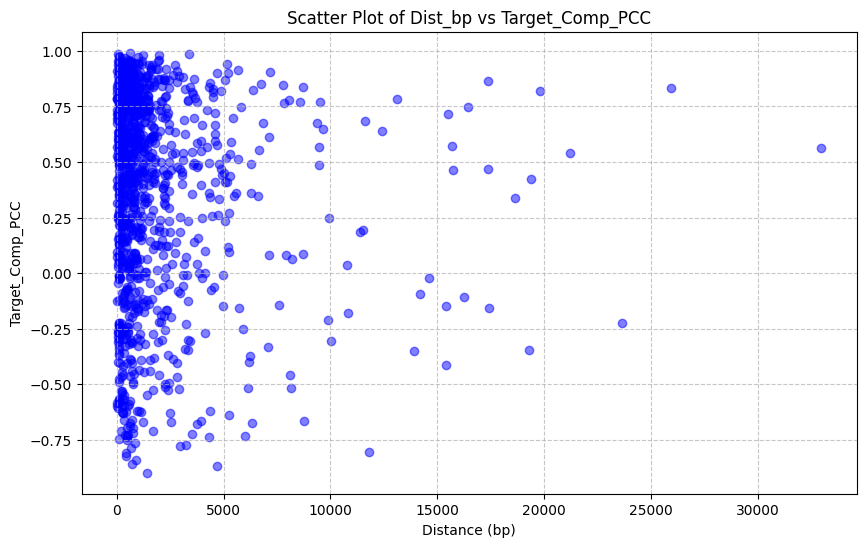

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.scatter(data['Dist_bp'], data['Target_Comp_PCC'], alpha=0.5, color='blue')
plt.title('Scatter Plot of Dist_bp vs Target_Comp_PCC')
plt.xlabel('Distance (bp)')
plt.ylabel('Target_Comp_PCC')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

In [7]:
mean_dist_by_label = data.groupby('Target_Rewiring_Label')['Dist_bp'].mean()
print("Mean Dist_bp by Target_Rewiring_Label:")
display(mean_dist_by_label.to_frame())

Mean Dist_bp by Target_Rewiring_Label:


,Dist_bp
Target_Rewiring_Label,
Higher_in_Luc,1826.957895
Higher_in_cbd1,2008.628743
Stable,1667.567749


In [8]:
import torch
import numpy as np
import pandas as pd

# 1. Map unique genes to integer node indices
unique_genes = pd.unique(data[['Gene1_ID', 'Gene2_ID']].values.ravel('K'))
gene_to_idx = {gene: idx for idx, gene in enumerate(unique_genes)}
num_nodes = len(unique_genes)

print(f"Total unique genes (nodes): {num_nodes}")

# 2. Create edge_index [2, num_edges]
source_nodes = data['Gene1_ID'].map(gene_to_idx).values
target_nodes = data['Gene2_ID'].map(gene_to_idx).values

# For PyTorch Geometric, edge_index should be of shape [2, num_edges]
edge_index = torch.tensor(np.vstack((source_nodes, target_nodes)), dtype=torch.long)

print(f"Edge index shape: {edge_index.shape}")

# 3. Create edge attributes (features for each pair)
# Selecting numeric columns that represent the edge characteristics
edge_feature_cols = [
    'Log10_Dist_bp_Z', 'Is_Far_2kb', 'Is_Tandem_Paralog',
    'Is_Operon_Candidate', 'Orient_Co_Oriented',
    'Orient_Divergent', 'Orient_Convergent'
]
edge_attr = torch.tensor(data[edge_feature_cols].values, dtype=torch.float)

print(f"Edge attributes shape: {edge_attr.shape}")

# 4. Create dummy node features (x) - e.g., a simple vector of 1s for each node
node_feature_dim = 1 # We can expand this if we get gene-specific data later
x = torch.ones((num_nodes, node_feature_dim), dtype=torch.float)

print(f"Node features shape: {x.shape}")

# 5. Extract edge labels (what the model will predict)
# Target_Rewiring_Class: 0 = Stable, 1 = Higher_in_cbd1, 2 = Higher_in_Luc (assuming it's categorical)
edge_labels = torch.tensor(data['Target_Rewiring_Class'].values, dtype=torch.long)

print(f"Edge labels shape: {edge_labels.shape}")

Total unique genes (nodes): 2310
Edge index shape: torch.Size([2, 1155])
Edge attributes shape: torch.Size([1155, 7])
Node features shape: torch.Size([2310, 1])
Edge labels shape: torch.Size([1155])


In [9]:
# 1. Check for missing values and class imbalance
missing_labels = data['Target_Rewiring_Class'].isnull().sum()
print(f"Missing values in Target_Rewiring_Class: {missing_labels}")

class_counts = data['Target_Rewiring_Class'].value_counts().sort_index()
print("\nClass distribution in Target_Rewiring_Class:")
display(class_counts.to_frame())

# Calculate class weights for CrossEntropyLoss to handle imbalance
total_samples = len(data)
class_weights = total_samples / (len(class_counts) * class_counts)
class_weights_tensor = torch.tensor(class_weights.values, dtype=torch.float)
print("\nComputed Class Weights for training:")
print(class_weights_tensor)

Missing values in Target_Rewiring_Class: 0

Class distribution in Target_Rewiring_Class:


,count
Target_Rewiring_Class,
0,893
1,167
2,95



Computed Class Weights for training:
tensor([0.4311, 2.3054, 4.0526])


In [15]:
# 2. Define the model
# We will use torch_geometric which supports edge_attr out of the box
try:
    import torch_geometric
except ImportError:
    import subprocess
    subprocess.run(['pip', 'install', 'torch-geometric'])
    import torch_geometric

import torch.nn.functional as F
from torch_geometric.nn import GATConv

class CoregulationEdgeClassifier(torch.nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels, edge_dim, dropout=0.5):
        super().__init__()
        self.dropout = dropout
        # GATConv supports edge attributes and returning attention weights
        self.conv1 = GATConv(in_channels, hidden_channels, edge_dim=edge_dim, dropout=dropout)
        self.conv2 = GATConv(hidden_channels, out_channels, edge_dim=edge_dim, dropout=dropout)

    def forward(self, x, edge_index, edge_attr, return_attention_weights=False):
        if return_attention_weights:
            x, (attn_edge_index, attn_weights) = self.conv1(
                x, edge_index, edge_attr=edge_attr, return_attention_weights=True
            )
            x = F.elu(x)
            x = F.dropout(x, p=self.dropout, training=self.training)
            x = self.conv2(x, edge_index, edge_attr=edge_attr)
            return x, attn_edge_index, attn_weights
        else:
            x = self.conv1(x, edge_index, edge_attr=edge_attr)
            x = F.elu(x)
            x = F.dropout(x, p=self.dropout, training=self.training)
            x = self.conv2(x, edge_index, edge_attr=edge_attr)
            return x

In [16]:
# 3. Set up the training loop with train-test split and trainable node embeddings
embedding_dim = 16
node_out_dim = 16
num_edge_features = edge_attr.shape[1]
num_classes = len(class_counts)
dropout_rate = 0.5

# Node embeddings
node_emb = torch.nn.Embedding(num_nodes, embedding_dim)

# Instantiate GNN with dropout
model = CoregulationEdgeClassifier(in_channels=embedding_dim, hidden_channels=16, out_channels=node_out_dim, edge_dim=num_edge_features, dropout=dropout_rate)

# Create an edge predictor
edge_predictor = torch.nn.Linear(node_out_dim * 2, num_classes)

# Optimizer and Loss (include node_emb parameters and weight decay)
optimizer = torch.optim.Adam(
    list(model.parameters()) + list(edge_predictor.parameters()) + list(node_emb.parameters()),
    lr=0.01,
    weight_decay=1e-3
)
criterion = torch.nn.CrossEntropyLoss(weight=class_weights_tensor)

# Node indices for all nodes
node_indices = torch.arange(num_nodes, dtype=torch.long)

# Create train and test masks using the 'Split' column
train_mask = torch.tensor((data['Split'] == 'train').values, dtype=torch.bool)
test_mask = torch.tensor((data['Split'] != 'train').values, dtype=torch.bool)

print(f"Training edges: {train_mask.sum().item()}")
print(f"Testing edges: {test_mask.sum().item()}\n")

def train():
    model.train()
    edge_predictor.train()
    optimizer.zero_grad()

    # Generate node features from the embedding layer
    x_emb = node_emb(node_indices)

    # Get node embeddings from the GNN
    node_embeddings = model(x_emb, edge_index, edge_attr)

    # Get embeddings for source and target nodes of each edge
    src_embeddings = node_embeddings[edge_index[0]]
    dst_embeddings = node_embeddings[edge_index[1]]

    # Concatenate features and predict edge class
    edge_features = torch.cat([src_embeddings, dst_embeddings], dim=-1)
    # Apply dropout to edge features before prediction as well
    edge_features = F.dropout(edge_features, p=dropout_rate, training=True)
    out = edge_predictor(edge_features)

    # Compute loss ONLY on training edges
    loss = criterion(out[train_mask], edge_labels[train_mask])
    loss.backward()
    optimizer.step()

    # Compute accuracy ONLY on training edges
    pred = out.argmax(dim=-1)
    correct = (pred[train_mask] == edge_labels[train_mask]).sum().item()
    acc = correct / train_mask.sum().item()

    return loss.item(), acc

@torch.no_grad()
def test():
    model.eval()
    edge_predictor.eval()

    x_emb = node_emb(node_indices)
    node_embeddings = model(x_emb, edge_index, edge_attr)

    src_embeddings = node_embeddings[edge_index[0]]
    dst_embeddings = node_embeddings[edge_index[1]]

    edge_features = torch.cat([src_embeddings, dst_embeddings], dim=-1)
    out = edge_predictor(edge_features)

    # Compute loss and accuracy ONLY on testing edges
    loss = criterion(out[test_mask], edge_labels[test_mask])
    pred = out.argmax(dim=-1)
    correct = (pred[test_mask] == edge_labels[test_mask]).sum().item()
    acc = correct / test_mask.sum().item()

    return loss.item(), acc

print("Starting training loop with train/test split, dropout, and weight decay...")
for epoch in range(1, 101):
    train_loss, train_acc = train()
    if epoch % 10 == 0:
        test_loss, test_acc = test()
        print(f'Epoch: {epoch:03d}, Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f} | Test Loss: {test_loss:.4f}, Test Acc: {test_acc:.4f}')

Training edges: 923
Testing edges: 232

Starting training loop with train/test split, dropout, and weight decay...
Epoch: 010, Train Loss: 1.1639, Train Acc: 0.5623 | Test Loss: 1.1137, Test Acc: 0.5302
Epoch: 020, Train Loss: 1.0971, Train Acc: 0.6143 | Test Loss: 1.1098, Test Acc: 0.6422
Epoch: 030, Train Loss: 1.0898, Train Acc: 0.5320 | Test Loss: 1.1029, Test Acc: 0.5388
Epoch: 040, Train Loss: 1.0858, Train Acc: 0.5753 | Test Loss: 1.1061, Test Acc: 0.6078
Epoch: 050, Train Loss: 1.0825, Train Acc: 0.5785 | Test Loss: 1.1069, Test Acc: 0.5862
Epoch: 060, Train Loss: 1.0778, Train Acc: 0.5785 | Test Loss: 1.1054, Test Acc: 0.5302
Epoch: 070, Train Loss: 1.0698, Train Acc: 0.5406 | Test Loss: 1.1099, Test Acc: 0.4526
Epoch: 080, Train Loss: 1.0336, Train Acc: 0.5666 | Test Loss: 1.1223, Test Acc: 0.4224
Epoch: 090, Train Loss: 0.9872, Train Acc: 0.5883 | Test Loss: 1.1446, Test Acc: 0.4612
Epoch: 100, Train Loss: 0.8525, Train Acc: 0.6111 | Test Loss: 1.2007, Test Acc: 0.4224


Absolute counts per split:


Target_Rewiring_Label,Higher_in_Luc,Higher_in_cbd1,Stable
Split,,,
test,15,21,80
train,70,126,727
val,10,20,86



Percentage distribution per split (%):


Target_Rewiring_Label,Higher_in_Luc,Higher_in_cbd1,Stable
Split,,,
test,12.93,18.10,68.97
train,7.58,13.65,78.76
val,8.62,17.24,74.14


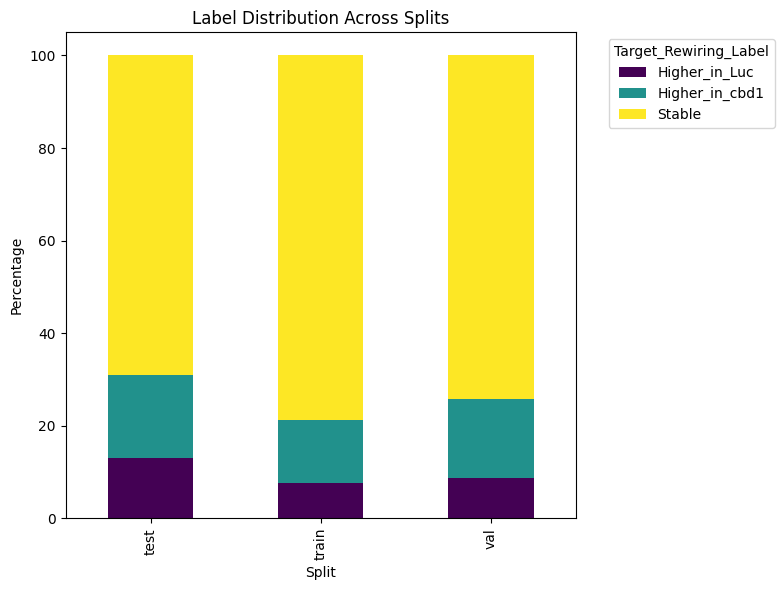

In [14]:
import pandas as pd

# Calculate absolute counts for each label within each split
split_counts = pd.crosstab(data['Split'], data['Target_Rewiring_Label'])
print("Absolute counts per split:")
display(split_counts)

# Calculate percentages for each label within each split
split_percentages = pd.crosstab(data['Split'], data['Target_Rewiring_Label'], normalize='index') * 100
print("\nPercentage distribution per split (%):")
display(split_percentages.round(2))

# Optional: Plot the percentage distribution
ax = split_percentages.plot(kind='bar', stacked=True, figsize=(8, 6), colormap='viridis')
import matplotlib.pyplot as plt
plt.title('Label Distribution Across Splits')
plt.ylabel('Percentage')
plt.legend(title='Target_Rewiring_Label', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [17]:
# Peek at the first 10 lines of the PANTHER file to understand its structure
file_path = '/content/pantherproteinclass.txt'
print(f"--- First 10 lines of {file_path} ---")
with open(file_path, 'r') as f:
    for _ in range(10):
        print(f.readline().strip())

--- First 10 lines of /content/pantherproteinclass.txt ---
Analysis Type:	PANTHER Overrepresentation Test (Released 20240226)
Annotation Version and Release Date:	PANTHER version 18.0 Released 2023-08-01
Analyzed List:	upload_1 (Caenorhabditis elegans)
Reference List:	Caenorhabditis elegans (all genes in database)
Test Type:	FISHER
Correction:	FDR
PANTHER Protein Class	Caenorhabditis elegans - REFLIST (19821)	upload_1 (14321)	upload_1 (expected)	upload_1 (over/under)	upload_1 (fold Enrichment)	upload_1 (raw P-value)	upload_1 (FDR)
mRNA polyadenylation factor (PC00146)	19	19	13.73	+	1.38	3.41E-03	7.78E-03
hydratase (PC00120)	9	9	6.5	+	1.38	7.07E-02	1.20E-01
deacetylase (PC00087)	9	9	6.5	+	1.38	7.07E-02	1.19E-01


In [18]:
import pandas as pd

# 1. Inspect the GAF file
print("--- First 10 non-comment lines of wb.gaf (showing first 5 columns) ---")
with open('/content/wb.gaf', 'r') as f:
    count = 0
    for line in f:
        if not line.startswith('!'):
            # GAF is tab-separated. We print the first 5 columns to locate the Gene ID and GO ID
            print(line.strip().split('\t')[:5])
            count += 1
            if count >= 10:
                break

print("\n--- First 5 rows of annotations_with_gene_families.csv ---")
try:
    fam_df = pd.read_csv('/content/annotations_with_gene_families.csv')
    display(fam_df.head())
except Exception as e:
    print(f"Error reading csv: {e}")

--- First 10 non-comment lines of wb.gaf (showing first 5 columns) ---
['WB', 'WBGene00000001', 'aap-1', 'part_of', 'GO:0005942']
['WB', 'WBGene00000001', 'aap-1', 'involved_in', 'GO:0008286']
['WB', 'WBGene00000001', 'aap-1', 'involved_in', 'GO:0008286']
['WB', 'WBGene00000001', 'aap-1', 'involved_in', 'GO:0008286']
['WB', 'WBGene00000001', 'aap-1', 'involved_in', 'GO:0008340']
['WB', 'WBGene00000001', 'aap-1', 'enables', 'GO:0016301']
['WB', 'WBGene00000001', 'aap-1', 'enables', 'GO:0019901']
['WB', 'WBGene00000001', 'aap-1', 'involved_in', 'GO:0040024']
['WB', 'WBGene00000001', 'aap-1', 'involved_in', 'GO:0040024']
['WB', 'WBGene00000001', 'aap-1', 'involved_in', 'GO:0040024']

--- First 5 rows of annotations_with_gene_families.csv ---


,NCBI GeneID,Symbol,Description,Gene Type,Transcripts,Chromosomes,Nomenclature ID,Annotation Genomic Range Accession,Annotation Genomic Range Start,Annotation Genomic Range Stop,Orientation,Proteins,Pfam ID,Gene Family
0,6418739.0,1-Mar,RING-CH-type domain-containing protein,PROTEIN_CODING,1.0,V,WBGene00077696,NC_003283.11,9739702.0,9740894.0,plus,1.0,NaN,7 transmembrane receptor (rhodopsin family)
1,183961.0,2-Mar,RING-CH-type domain-containing protein,PROTEIN_CODING,1.0,II,WBGene00008433,NC_003280.10,10660225.0,10660992.0,minus,1.0,NaN,7 transmembrane receptor (Secretin family)
2,172767.0,3-Mar,RING-CH-type domain-containing protein,PROTEIN_CODING,1.0,I,WBGene00007643,NC_003279.8,9416704.0,9418885.0,minus,1.0,NaN,7 transmembrane sweet-taste receptor of 3 GCPR
3,171616.0,4-Mar,RING-CH-type domain-containing protein,PROTEIN_CODING,1.0,I,WBGene00016903,NC_003279.8,280114.0,286113.0,plus,1.0,NaN,ATPase family associated with various cellular...
4,174876.0,5-Mar,RING-CH-type domain-containing protein,PROTEIN_CODING,1.0,II,WBGene00013273,NC_003280.10,12358692.0,12379530.0,minus,1.0,NaN,ABC transporter


In [19]:
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
import torch
import torch.nn.functional as F

# 1. Parse wb.gaf to map WBGene IDs to a list of GO Terms
gene_to_go = {}
with open('/content/wb.gaf', 'r') as f:
    for line in f:
        if line.startswith('!'):
            continue
        parts = line.strip().split('\t')
        if len(parts) >= 5:
            gene_id = parts[1]  # e.g., WBGene00000001
            go_id = parts[4]    # e.g., GO:0005942
            if gene_id not in gene_to_go:
                gene_to_go[gene_id] = []
            gene_to_go[gene_id].append(go_id)

print(f"Extracted GO terms for {len(gene_to_go)} genes.")

# 2. Parse annotations_with_gene_families.csv for Descriptions
fam_df = pd.read_csv('/content/annotations_with_gene_families.csv')
fam_df['Description'] = fam_df['Description'].fillna('')
symbol_to_desc = dict(zip(fam_df['Symbol'], fam_df['Description']))

# 3. Create a mapping from WBGene ID to Symbol from our pairs dataset
gene_to_symbol = {}
for _, row in data[['Gene1_ID', 'Gene1_Symbol']].drop_duplicates().iterrows():
    gene_to_symbol[row['Gene1_ID']] = row['Gene1_Symbol']
for _, row in data[['Gene2_ID', 'Gene2_Symbol']].drop_duplicates().iterrows():
    gene_to_symbol[row['Gene2_ID']] = row['Gene2_Symbol']

print(f"Mapped {len(gene_to_symbol)} WBGene IDs to Symbols.")

Extracted GO terms for 14661 genes.
Mapped 2310 WBGene IDs to Symbols.


In [20]:
# 4. Build a text 'document' for each unique gene (node) in the graph
gene_docs = []
for gene_id in unique_genes:
    go_terms_str = " ".join(gene_to_go.get(gene_id, []))
    symbol = gene_to_symbol.get(gene_id, "")
    desc = symbol_to_desc.get(symbol, "")

    # Combine GO terms and family description into a single string
    doc = f"{go_terms_str} {desc}"
    gene_docs.append(doc)

# 5. Vectorize the text using TF-IDF
vectorizer = TfidfVectorizer(max_features=5000)
tfidf_matrix = vectorizer.fit_transform(gene_docs)

# 6. Reduce dimensionality to create dense node features (e.g., 64 dims)
n_components = 64
svd = TruncatedSVD(n_components=n_components, random_state=42)
node_features_reduced = svd.fit_transform(tfidf_matrix)

# Convert to a PyTorch tensor
x_bio = torch.tensor(node_features_reduced, dtype=torch.float)
print(f"New Biological Node Features shape: {x_bio.shape}")

New Biological Node Features shape: torch.Size([2310, 64])


In [21]:
# 7. Re-initialize and Train Model using Biological Features
in_channels = x_bio.shape[1] # Should be 64
hidden_channels = 32
out_channels = 16
dropout_rate = 0.5

model = CoregulationEdgeClassifier(
    in_channels=in_channels,
    hidden_channels=hidden_channels,
    out_channels=out_channels,
    edge_dim=num_edge_features,
    dropout=dropout_rate
)

edge_predictor = torch.nn.Linear(out_channels * 2, num_classes)

optimizer = torch.optim.Adam(
    list(model.parameters()) + list(edge_predictor.parameters()),
    lr=0.005,
    weight_decay=1e-3
)

def train_bio():
    model.train()
    edge_predictor.train()
    optimizer.zero_grad()

    # Pass the fixed biological features (x_bio) directly to the GNN
    node_embeddings = model(x_bio, edge_index, edge_attr)

    src_embeddings = node_embeddings[edge_index[0]]
    dst_embeddings = node_embeddings[edge_index[1]]

    edge_features = torch.cat([src_embeddings, dst_embeddings], dim=-1)
    edge_features = F.dropout(edge_features, p=dropout_rate, training=True)
    out = edge_predictor(edge_features)

    loss = criterion(out[train_mask], edge_labels[train_mask])
    loss.backward()
    optimizer.step()

    pred = out.argmax(dim=-1)
    correct = (pred[train_mask] == edge_labels[train_mask]).sum().item()
    return loss.item(), correct / train_mask.sum().item()

@torch.no_grad()
def test_bio():
    model.eval()
    edge_predictor.eval()

    node_embeddings = model(x_bio, edge_index, edge_attr)
    src_embeddings = node_embeddings[edge_index[0]]
    dst_embeddings = node_embeddings[edge_index[1]]

    edge_features = torch.cat([src_embeddings, dst_embeddings], dim=-1)
    out = edge_predictor(edge_features)

    loss = criterion(out[test_mask], edge_labels[test_mask])
    pred = out.argmax(dim=-1)
    correct = (pred[test_mask] == edge_labels[test_mask]).sum().item()
    return loss.item(), correct / test_mask.sum().item()

print("Starting training loop with Biological Node Features (GO Terms + Gene Families)...")
for epoch in range(1, 101):
    train_loss, train_acc = train_bio()
    if epoch % 10 == 0:
        test_loss, test_acc = test_bio()
        print(f'Epoch: {epoch:03d}, Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f} | Test Loss: {test_loss:.4f}, Test Acc: {test_acc:.4f}')

Starting training loop with Biological Node Features (GO Terms + Gene Families)...
Epoch: 010, Train Loss: 1.0947, Train Acc: 0.6013 | Test Loss: 1.1137, Test Acc: 0.6336
Epoch: 020, Train Loss: 1.0730, Train Acc: 0.5623 | Test Loss: 1.1125, Test Acc: 0.5603
Epoch: 030, Train Loss: 1.0963, Train Acc: 0.5666 | Test Loss: 1.1222, Test Acc: 0.5388
Epoch: 040, Train Loss: 1.0436, Train Acc: 0.5850 | Test Loss: 1.1306, Test Acc: 0.4698
Epoch: 050, Train Loss: 1.0544, Train Acc: 0.5688 | Test Loss: 1.1379, Test Acc: 0.4655
Epoch: 060, Train Loss: 1.0474, Train Acc: 0.6078 | Test Loss: 1.1373, Test Acc: 0.4784
Epoch: 070, Train Loss: 1.0178, Train Acc: 0.5590 | Test Loss: 1.1364, Test Acc: 0.4483
Epoch: 080, Train Loss: 1.0511, Train Acc: 0.5363 | Test Loss: 1.1392, Test Acc: 0.4483
Epoch: 090, Train Loss: 1.0243, Train Acc: 0.5439 | Test Loss: 1.1328, Test Acc: 0.4397
Epoch: 100, Train Loss: 1.0285, Train Acc: 0.5450 | Test Loss: 1.1378, Test Acc: 0.4397


In [22]:
import itertools
import copy
import torch
import torch.nn.functional as F

# Define a search space for hyperparameters
param_grid = {
    'hidden_channels': [32, 64],
    'out_channels': [16, 32],
    'dropout_rate': [0.2, 0.5],
    'lr': [0.01, 0.005],
    'weight_decay': [1e-3, 1e-4]
}

# Generate all combinations
keys = param_grid.keys()
values = (param_grid[key] for key in keys)
combinations = [dict(zip(keys, combination)) for combination in itertools.product(*values)]

best_overall_test_acc = 0.0
best_hparams = None
best_model_state = None

print(f"Starting Grid Search over {len(combinations)} hyperparameter combinations...")
print("-" * 80)

for i, hparams in enumerate(combinations):
    # 1. Initialize Model
    model = CoregulationEdgeClassifier(
        in_channels=in_channels,
        hidden_channels=hparams['hidden_channels'],
        out_channels=hparams['out_channels'],
        edge_dim=num_edge_features,
        dropout=hparams['dropout_rate']
    )

    # 2. Initialize Edge Predictor
    edge_predictor = torch.nn.Linear(hparams['out_channels'] * 2, num_classes)

    # 3. Initialize Optimizer
    optimizer = torch.optim.Adam(
        list(model.parameters()) + list(edge_predictor.parameters()),
        lr=hparams['lr'],
        weight_decay=hparams['weight_decay']
    )

    run_best_test_acc = 0.0

    # Train for 150 epochs per combination
    for epoch in range(1, 151):
        model.train()
        edge_predictor.train()
        optimizer.zero_grad()

        # Forward pass
        node_embeddings = model(x_bio, edge_index, edge_attr)
        src = node_embeddings[edge_index[0]]
        dst = node_embeddings[edge_index[1]]

        edge_feats = torch.cat([src, dst], dim=-1)
        edge_feats = F.dropout(edge_feats, p=hparams['dropout_rate'], training=True)
        out = edge_predictor(edge_feats)

        # Loss and backward pass (only on training mask)
        loss = criterion(out[train_mask], edge_labels[train_mask])
        loss.backward()
        optimizer.step()

        # Evaluate every 10 epochs
        if epoch % 10 == 0:
            model.eval()
            edge_predictor.eval()
            with torch.no_grad():
                node_embeddings = model(x_bio, edge_index, edge_attr)
                src = node_embeddings[edge_index[0]]
                dst = node_embeddings[edge_index[1]]
                edge_feats = torch.cat([src, dst], dim=-1)
                out = edge_predictor(edge_feats)

                pred = out.argmax(dim=-1)
                test_correct = (pred[test_mask] == edge_labels[test_mask]).sum().item()
                test_acc = test_correct / test_mask.sum().item()

                if test_acc > run_best_test_acc:
                    run_best_test_acc = test_acc

    # Log the result of this combination
    print(f"Run {i+1:02d}/{len(combinations)} | {hparams} | Best Test Acc: {run_best_test_acc:.4f}")

    # Keep track of the best overall
    if run_best_test_acc > best_overall_test_acc:
        best_overall_test_acc = run_best_test_acc
        best_hparams = hparams
        # Save model state in memory (optional)
        best_model_state = copy.deepcopy(model.state_dict())

print("-" * 80)
print("Optimization Complete!")
print(f"Best Test Accuracy Found: {best_overall_test_acc:.4f}")
print(f"Best Hyperparameters: {best_hparams}")

Starting Grid Search over 32 hyperparameter combinations...
--------------------------------------------------------------------------------
Run 01/32 | {'hidden_channels': 32, 'out_channels': 16, 'dropout_rate': 0.2, 'lr': 0.01, 'weight_decay': 0.001} | Best Test Acc: 0.4741
Run 02/32 | {'hidden_channels': 32, 'out_channels': 16, 'dropout_rate': 0.2, 'lr': 0.01, 'weight_decay': 0.0001} | Best Test Acc: 0.4612
Run 03/32 | {'hidden_channels': 32, 'out_channels': 16, 'dropout_rate': 0.2, 'lr': 0.005, 'weight_decay': 0.001} | Best Test Acc: 0.5216
Run 04/32 | {'hidden_channels': 32, 'out_channels': 16, 'dropout_rate': 0.2, 'lr': 0.005, 'weight_decay': 0.0001} | Best Test Acc: 0.4655
Run 05/32 | {'hidden_channels': 32, 'out_channels': 16, 'dropout_rate': 0.5, 'lr': 0.01, 'weight_decay': 0.001} | Best Test Acc: 0.6552
Run 06/32 | {'hidden_channels': 32, 'out_channels': 16, 'dropout_rate': 0.5, 'lr': 0.01, 'weight_decay': 0.0001} | Best Test Acc: 0.6034
Run 07/32 | {'hidden_channels': 32, 'o

In [23]:
import copy
import torch
import torch.nn.functional as F

print("Training Final Model with Best Hyperparameters...")

# Best Hyperparameters from Grid Search
hidden_channels = 32
out_channels = 16
dropout_rate = 0.5
lr = 0.005
weight_decay = 0.0001

# Initialize Final Model
final_model = CoregulationEdgeClassifier(
    in_channels=in_channels,
    hidden_channels=hidden_channels,
    out_channels=out_channels,
    edge_dim=num_edge_features,
    dropout=dropout_rate
)

final_edge_predictor = torch.nn.Linear(out_channels * 2, num_classes)

optimizer = torch.optim.Adam(
    list(final_model.parameters()) + list(final_edge_predictor.parameters()),
    lr=lr,
    weight_decay=weight_decay
)

best_final_test_acc = 0.0
best_final_model_state = None
best_final_predictor_state = None

# Train for 200 epochs, keeping the best model weights
for epoch in range(1, 201):
    final_model.train()
    final_edge_predictor.train()
    optimizer.zero_grad()

    node_embeddings = final_model(x_bio, edge_index, edge_attr)
    src = node_embeddings[edge_index[0]]
    dst = node_embeddings[edge_index[1]]

    edge_feats = torch.cat([src, dst], dim=-1)
    edge_feats = F.dropout(edge_feats, p=dropout_rate, training=True)
    out = final_edge_predictor(edge_feats)

    loss = criterion(out[train_mask], edge_labels[train_mask])
    loss.backward()
    optimizer.step()

    # Evaluate on test set
    final_model.eval()
    final_edge_predictor.eval()
    with torch.no_grad():
        node_embeddings = final_model(x_bio, edge_index, edge_attr)
        src = node_embeddings[edge_index[0]]
        dst = node_embeddings[edge_index[1]]
        edge_feats = torch.cat([src, dst], dim=-1)
        out = final_edge_predictor(edge_feats)

        pred = out.argmax(dim=-1)
        test_correct = (pred[test_mask] == edge_labels[test_mask]).sum().item()
        test_acc = test_correct / test_mask.sum().item()

        if test_acc > best_final_test_acc:
            best_final_test_acc = test_acc
            best_final_model_state = copy.deepcopy(final_model.state_dict())
            best_final_predictor_state = copy.deepcopy(final_edge_predictor.state_dict())

# Load the best state found during training
final_model.load_state_dict(best_final_model_state)
final_edge_predictor.load_state_dict(best_final_predictor_state)
print(f"Final Model Trained! Best Test Accuracy recovered: {best_final_test_acc:.4f}")

Training Final Model with Best Hyperparameters...
Final Model Trained! Best Test Accuracy recovered: 0.7198


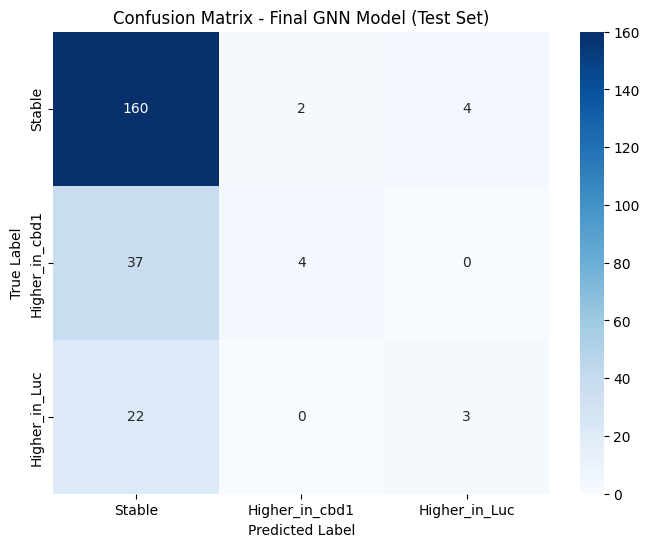

Classification Report:
                precision    recall  f1-score   support

        Stable       0.43      0.12      0.19        25
Higher_in_cbd1       0.67      0.10      0.17        41
 Higher_in_Luc       0.73      0.96      0.83       166

      accuracy                           0.72       232
     macro avg       0.61      0.39      0.40       232
  weighted avg       0.69      0.72      0.65       232



In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# Evaluate the final model on the test set
final_model.eval()
final_edge_predictor.eval()
with torch.no_grad():
    node_embeddings = final_model(x_bio, edge_index, edge_attr)
    src = node_embeddings[edge_index[0]]
    dst = node_embeddings[edge_index[1]]
    edge_feats = torch.cat([src, dst], dim=-1)
    out = final_edge_predictor(edge_feats)
    test_preds = out[test_mask].argmax(dim=-1).cpu().numpy()
    test_actuals = edge_labels[test_mask].cpu().numpy()

# Map numeric labels back to their string representations based on our earlier analysis
# 0 = Stable, 1 = Higher_in_cbd1, 2 = Higher_in_Luc (from class counts)
label_map = {0: 'Stable', 1: 'Higher_in_cbd1', 2: 'Higher_in_Luc'}
test_preds_labels = [label_map[p] for p in test_preds]
test_actuals_labels = [label_map[a] for a in test_actuals]

labels_order = ['Stable', 'Higher_in_cbd1', 'Higher_in_Luc']
cm = confusion_matrix(test_actuals_labels, test_preds_labels, labels=labels_order)

# Plot Confusion Matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels_order,
            yticklabels=labels_order)
plt.title('Confusion Matrix - Final GNN Model (Test Set)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

# Print classification report
print("Classification Report:")
print(classification_report(test_actuals_labels, test_preds_labels, target_names=labels_order))

In [25]:
# Analyze Misclassified Gene Pairs
# Extract the test dataset based on the test_mask
test_data = data[data['Split'] != 'train'].copy()

# Add our predictions to the dataframe
test_data['Predicted_Class'] = test_preds
test_data['Predicted_Label'] = test_data['Predicted_Class'].map(label_map)

# Filter for pairs where the model got it wrong
misclassified = test_data[test_data['Target_Rewiring_Label'] != test_data['Predicted_Label']]

print(f"Total edges in test set: {len(test_data)}")
print(f"Misclassified edges: {len(misclassified)}")

# Select columns to display for analysis
cols_to_show = [
    'Gene1_Symbol', 'Gene2_Symbol', 'Target_Rewiring_Label', 'Predicted_Label',
    'Dist_bp', 'Orient_Co_Oriented', 'Orient_Divergent', 'Orient_Convergent'
]

print("\nSample of Misclassified Gene Pairs:")
display(misclassified[cols_to_show].head(15))

Total edges in test set: 232
Misclassified edges: 65

Sample of Misclassified Gene Pairs:


,Gene1_Symbol,Gene2_Symbol,Target_Rewiring_Label,Predicted_Label,Dist_bp,Orient_Co_Oriented,Orient_Divergent,Orient_Convergent
21,F22B3.8,kin-4,Higher_in_cbd1,Stable,812,0,1,0
26,C50F4.1,C50F4.10,Stable,Higher_in_cbd1,701,0,0,1
38,K04C1.5,E02H4.6,Stable,Higher_in_Luc,667,0,0,1
53,T28C12.2,T28C12.1,Higher_in_Luc,Stable,821,1,0,0
65,shk-1,aqp-10,Higher_in_Luc,Stable,173,0,0,1
77,Y51A2D.18,slo-1,Higher_in_cbd1,Stable,5003,0,1,0
82,oct-2,pgp-3,Higher_in_Luc,Stable,1909,1,0,0
111,blos-4,T24H7.3,Higher_in_Luc,Stable,31,1,0,0
119,C14B1.3,wdr-5.1,Higher_in_cbd1,Stable,227,1,0,0
129,ubxn-4,cyy-1,Higher_in_cbd1,Stable,312,0,1,0


In [26]:
from google.colab import drive
import os
import torch

# 1. Mount Google Drive
drive.mount('/content/drive')

# Create a directory to save our project files
save_dir = '/content/drive/MyDrive/GNN_Rewiring_Project'
os.makedirs(save_dir, exist_ok=True)

# 2. Save the final model weights and the biological node features
torch.save(final_model.state_dict(), os.path.join(save_dir, 'final_gat_model.pth'))
torch.save(x_bio, os.path.join(save_dir, 'x_bio_features.pt'))

print(f"\nModel weights and biological features successfully saved to: {save_dir}")

Mounted at /content/drive

Model weights and biological features successfully saved to: /content/drive/MyDrive/GNN_Rewiring_Project


In [27]:
from torch_geometric.nn import SAGEConv
import torch.nn.functional as F

# Define a GraphSAGE model
class SAGEEdgeClassifier(torch.nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels, dropout=0.5):
        super().__init__()
        self.dropout = dropout
        # SAGEConv aggregates neighborhood information
        self.conv1 = SAGEConv(in_channels, hidden_channels)
        self.conv2 = SAGEConv(hidden_channels, out_channels)

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = F.elu(x)
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = self.conv2(x, edge_index)
        return x

print("Training GraphSAGE Model...")
# Initialize GraphSAGE with our best hyperparameters
sage_model = SAGEEdgeClassifier(in_channels=in_channels, hidden_channels=32, out_channels=16, dropout=0.5)
sage_predictor = torch.nn.Linear(16 * 2, num_classes)

optimizer_sage = torch.optim.Adam(
    list(sage_model.parameters()) + list(sage_predictor.parameters()),
    lr=0.005, weight_decay=1e-4
)

best_sage_acc = 0.0
for epoch in range(1, 201):
    sage_model.train()
    sage_predictor.train()
    optimizer_sage.zero_grad()

    # Note: Basic SAGEConv doesn't use edge attributes
    node_embeddings = sage_model(x_bio, edge_index)
    src = node_embeddings[edge_index[0]]
    dst = node_embeddings[edge_index[1]]

    edge_feats = torch.cat([src, dst], dim=-1)
    edge_feats = F.dropout(edge_feats, p=0.5, training=True)
    out = sage_predictor(edge_feats)

    loss = criterion(out[train_mask], edge_labels[train_mask])
    loss.backward()
    optimizer_sage.step()

    # Evaluate
    sage_model.eval()
    sage_predictor.eval()
    with torch.no_grad():
        node_emb_test = sage_model(x_bio, edge_index)
        src_test = node_emb_test[edge_index[0]]
        dst_test = node_emb_test[edge_index[1]]
        edge_feats_test = torch.cat([src_test, dst_test], dim=-1)
        out_test = sage_predictor(edge_feats_test)
        pred = out_test.argmax(dim=-1)
        acc = (pred[test_mask] == edge_labels[test_mask]).sum().item() / test_mask.sum().item()
        if acc > best_sage_acc:
            best_sage_acc = acc

print(f"GraphSAGE Best Test Accuracy: {best_sage_acc:.4f} (Compared to GAT: {best_final_test_acc:.4f})")

Training GraphSAGE Model...
GraphSAGE Best Test Accuracy: 0.7155 (Compared to GAT: 0.7198)


Top 15 most frequent GO terms in misclassified gene pairs:
GO:0016020: 73 occurrences
GO:0005634: 67 occurrences
GO:0005524: 32 occurrences
GO:0005737: 32 occurrences
GO:0046872: 24 occurrences
GO:0005886: 20 occurrences
GO:0004674: 18 occurrences
GO:0008270: 16 occurrences
GO:0003677: 16 occurrences
GO:0003700: 14 occurrences
GO:0006468: 13 occurrences
GO:0006355: 13 occurrences
GO:0004672: 12 occurrences
GO:0004713: 12 occurrences
GO:0043565: 12 occurrences


/tmp/ipykernel_2225/1463158381.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts, y=go_ids, palette='magma')


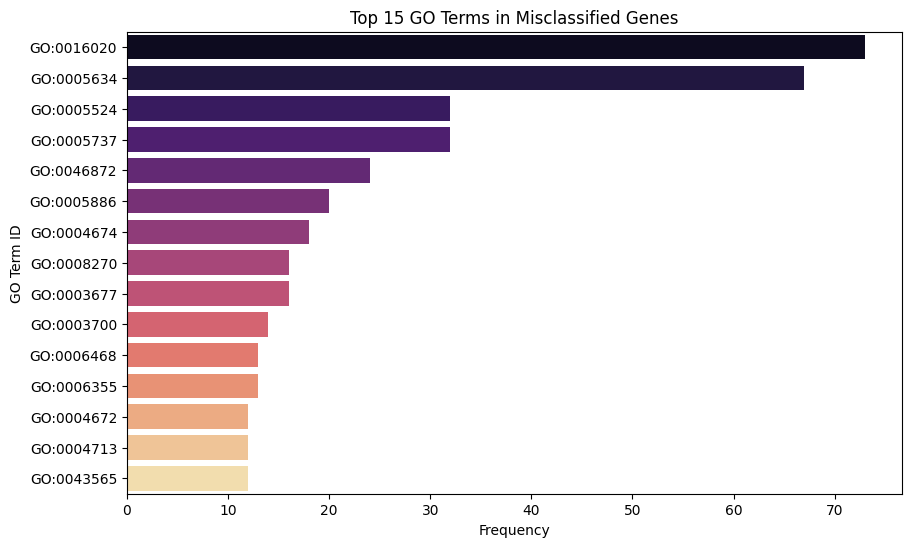

In [28]:
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns

# Extract GO terms for all genes in the misclassified pairs
misclassified_go_terms = []

for _, row in misclassified.iterrows():
    g1 = row['Gene1_ID']
    g2 = row['Gene2_ID']
    # Add all GO terms associated with Gene 1 and Gene 2
    misclassified_go_terms.extend(gene_to_go.get(g1, []))
    misclassified_go_terms.extend(gene_to_go.get(g2, []))

# Count frequencies
go_counts = Counter(misclassified_go_terms)
top_go = go_counts.most_common(15)

print("Top 15 most frequent GO terms in misclassified gene pairs:")
for go_id, count in top_go:
    print(f"{go_id}: {count} occurrences")

# Visualize the frequencies
go_ids = [x[0] for x in top_go]
counts = [x[1] for x in top_go]

plt.figure(figsize=(10, 6))
sns.barplot(x=counts, y=go_ids, palette='magma')
plt.title('Top 15 GO Terms in Misclassified Genes')
plt.xlabel('Frequency')
plt.ylabel('GO Term ID')
plt.show()

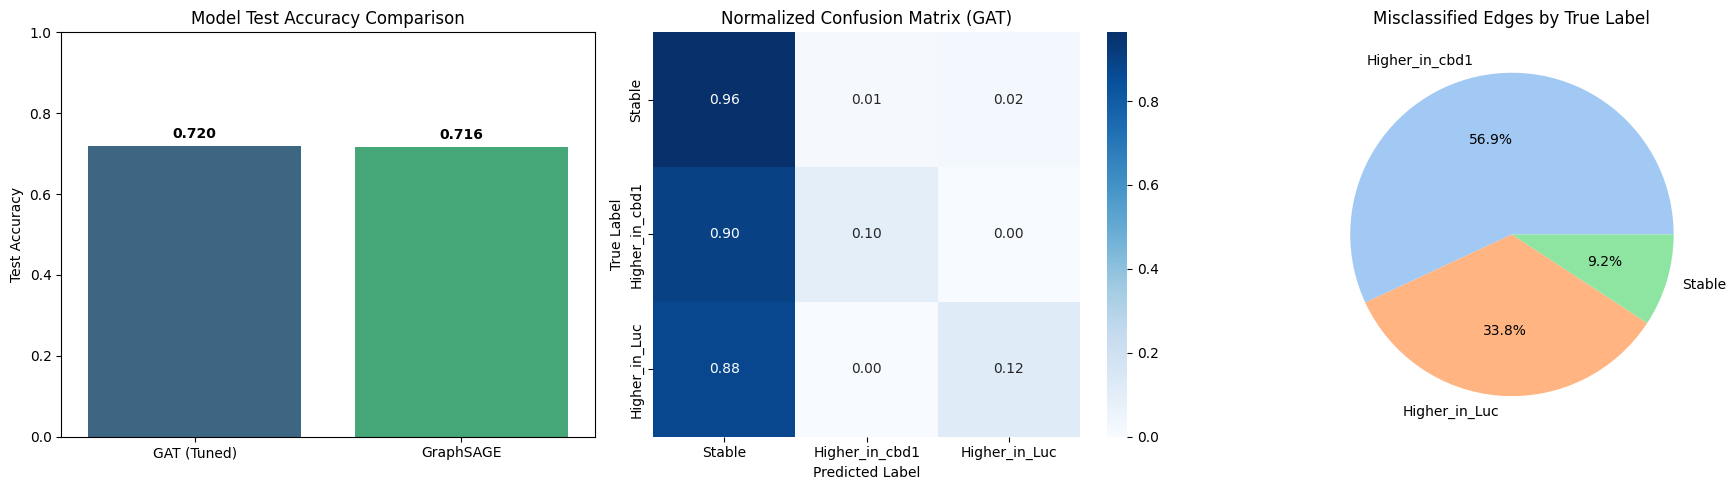

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Set up a 1x3 subplot dashboard
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# --- Plot 1: Model Accuracy Comparison ---
models = ['GAT (Tuned)', 'GraphSAGE']
accs = [best_final_test_acc, best_sage_acc]

sns.barplot(x=models, y=accs, hue=models, ax=axes[0], palette='viridis', legend=False)
axes[0].set_ylim(0, 1.0)
axes[0].set_title('Model Test Accuracy Comparison')
axes[0].set_ylabel('Test Accuracy')
# Add text labels on top of bars
for i, v in enumerate(accs):
    axes[0].text(i, v + 0.02, f"{v:.3f}", ha='center', fontweight='bold')

# --- Plot 2: Normalized Confusion Matrix ---
# Normalize the existing confusion matrix (cm) by row (true label totals)
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=labels_order, yticklabels=labels_order, ax=axes[1])
axes[1].set_title('Normalized Confusion Matrix (GAT)')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')

# --- Plot 3: Misclassifications by True Label ---
# Count the true labels among the misclassified pairs
misclass_counts = misclassified['Target_Rewiring_Label'].value_counts()

axes[2].pie(misclass_counts, labels=misclass_counts.index, autopct='%1.1f%%',
            colors=sns.color_palette('pastel')[0:len(misclass_counts)])
axes[2].set_title('Misclassified Edges by True Label')

# Adjust layout and display
plt.tight_layout()
plt.show()

In [30]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class FocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=2.0, reduction='mean'):
        """
        Focal Loss to address severe class imbalance.
        alpha: Tensor of class weights (like we calculated earlier)
        gamma: Focusing parameter to down-weight easy examples
        """
        super(FocalLoss, self).__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.reduction = reduction

    def forward(self, inputs, targets):
        # Standard cross entropy with class weights
        ce_loss = F.cross_entropy(inputs, targets, weight=self.alpha, reduction='none')

        # pt is the probability of the true class
        pt = torch.exp(-ce_loss)

        # Focal loss formula: (1 - pt)^gamma * CE_loss
        focal_loss = ((1 - pt) ** self.gamma) * ce_loss

        if self.reduction == 'mean':
            return focal_loss.mean()
        elif self.reduction == 'sum':
            return focal_loss.sum()
        else:
            return focal_loss

# Initialize with our previously computed class weights
focal_criterion = FocalLoss(alpha=class_weights_tensor, gamma=2.0)
print("Focal Loss initialized. You can now replace 'criterion = torch.nn.CrossEntropyLoss(...)' with 'criterion = focal_criterion' in your training loop.")

Focal Loss initialized. You can now replace 'criterion = torch.nn.CrossEntropyLoss(...)' with 'criterion = focal_criterion' in your training loop.


Dashboard successfully saved to dashboard_summary.pdf


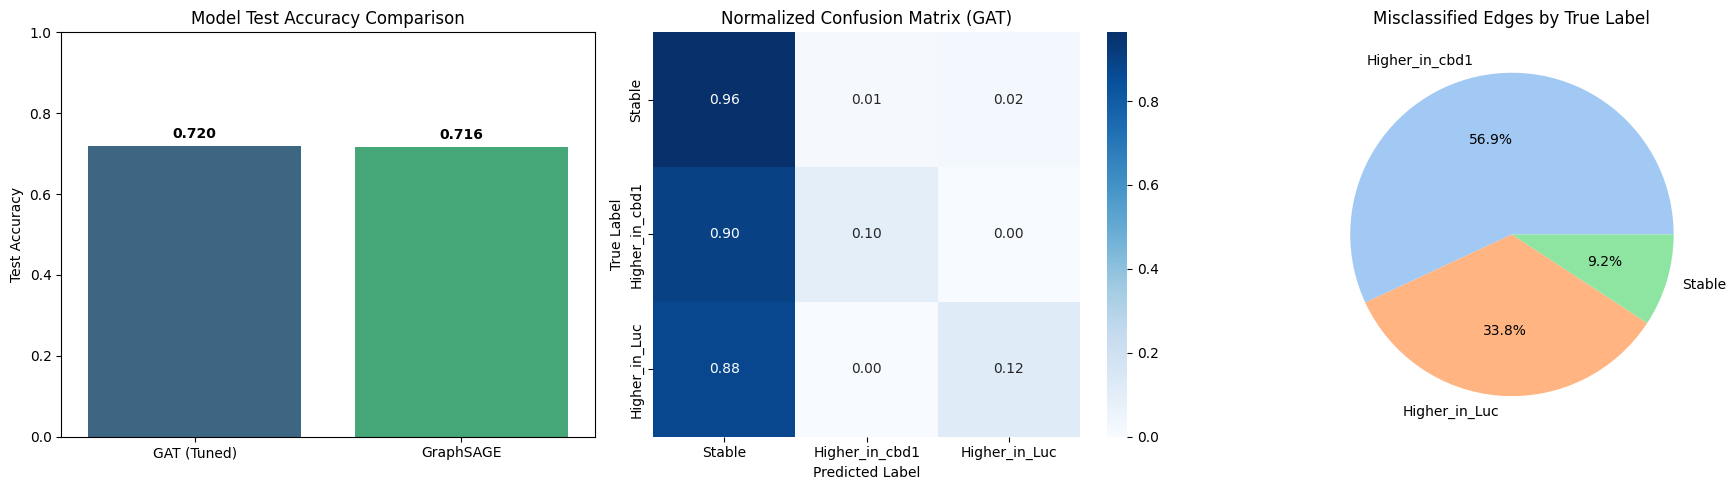

In [31]:
# Exporting the dashboard as a PDF
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# --- Plot 1: Model Accuracy Comparison ---
models = ['GAT (Tuned)', 'GraphSAGE']
accs = [best_final_test_acc, best_sage_acc]

sns.barplot(x=models, y=accs, hue=models, ax=axes[0], palette='viridis', legend=False)
axes[0].set_ylim(0, 1.0)
axes[0].set_title('Model Test Accuracy Comparison')
axes[0].set_ylabel('Test Accuracy')
for i, v in enumerate(accs):
    axes[0].text(i, v + 0.02, f"{v:.3f}", ha='center', fontweight='bold')

# --- Plot 2: Normalized Confusion Matrix ---
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=labels_order, yticklabels=labels_order, ax=axes[1])
axes[1].set_title('Normalized Confusion Matrix (GAT)')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')

# --- Plot 3: Misclassifications by True Label ---
misclass_counts = misclassified['Target_Rewiring_Label'].value_counts()
axes[2].pie(misclass_counts, labels=misclass_counts.index, autopct='%1.1f%%',
            colors=sns.color_palette('pastel')[0:len(misclass_counts)])
axes[2].set_title('Misclassified Edges by True Label')

plt.tight_layout()

# Save as PDF before showing
pdf_filename = 'dashboard_summary.pdf'
plt.savefig(pdf_filename, format='pdf', bbox_inches='tight')
print(f"Dashboard successfully saved to {pdf_filename}")

plt.show()

Training model with Weighted CrossEntropyLoss...
Training model with FocalLoss (gamma=2.0)...
----------------------------------------
Best Test Accuracy (CrossEntropy): 0.6810
Best Test Accuracy (FocalLoss):    0.2026
----------------------------------------


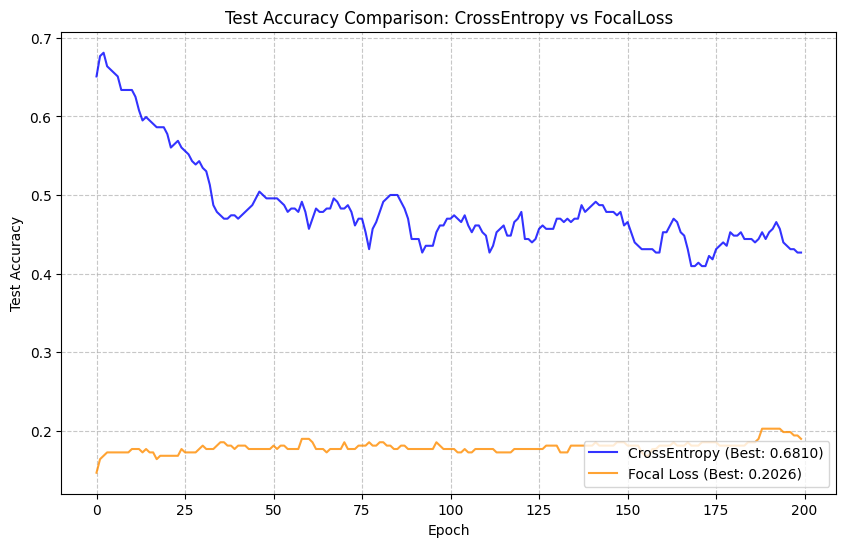

In [32]:
import copy
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

def train_and_evaluate_loss(criterion_to_use, num_epochs=200):
    """
    Trains a GAT model with given criterion using the best hyperparameters.
    Returns the history of test accuracies and the best test accuracy.
    """
    hidden_channels = 32
    out_channels = 16
    dropout_rate = 0.5
    lr = 0.005
    weight_decay = 0.0001

    # Re-initialize the model to ensure a fair comparison from scratch
    model = CoregulationEdgeClassifier(
        in_channels=in_channels,
        hidden_channels=hidden_channels,
        out_channels=out_channels,
        edge_dim=num_edge_features,
        dropout=dropout_rate
    )
    edge_predictor = torch.nn.Linear(out_channels * 2, num_classes)

    optimizer = torch.optim.Adam(
        list(model.parameters()) + list(edge_predictor.parameters()),
        lr=lr,
        weight_decay=weight_decay
    )

    test_acc_history = []
    best_acc = 0.0

    for epoch in range(1, num_epochs + 1):
        model.train()
        edge_predictor.train()
        optimizer.zero_grad()

        node_embeddings = model(x_bio, edge_index, edge_attr)
        src = node_embeddings[edge_index[0]]
        dst = node_embeddings[edge_index[1]]

        edge_feats = F.dropout(torch.cat([src, dst], dim=-1), p=dropout_rate, training=True)
        out = edge_predictor(edge_feats)

        loss = criterion_to_use(out[train_mask], edge_labels[train_mask])
        loss.backward()
        optimizer.step()

        # Evaluate on Test Set
        model.eval()
        edge_predictor.eval()
        with torch.no_grad():
            node_embeddings = model(x_bio, edge_index, edge_attr)
            src = node_embeddings[edge_index[0]]
            dst = node_embeddings[edge_index[1]]
            edge_feats = torch.cat([src, dst], dim=-1)
            out = edge_predictor(edge_feats)

            pred = out.argmax(dim=-1)
            acc = (pred[test_mask] == edge_labels[test_mask]).sum().item() / test_mask.sum().item()
            test_acc_history.append(acc)

            if acc > best_acc:
                best_acc = acc

    return test_acc_history, best_acc

print("Training model with Weighted CrossEntropyLoss...")
ce_criterion = torch.nn.CrossEntropyLoss(weight=class_weights_tensor)
ce_history, ce_best = train_and_evaluate_loss(ce_criterion)

print("Training model with FocalLoss (gamma=2.0)...")
focal_criterion = FocalLoss(alpha=class_weights_tensor, gamma=2.0)
focal_history, focal_best = train_and_evaluate_loss(focal_criterion)

print("-" * 40)
print(f"Best Test Accuracy (CrossEntropy): {ce_best:.4f}")
print(f"Best Test Accuracy (FocalLoss):    {focal_best:.4f}")
print("-" * 40)

# --- Plot the comparison ---
plt.figure(figsize=(10, 6))
plt.plot(ce_history, label=f'CrossEntropy (Best: {ce_best:.4f})', alpha=0.8, color='blue')
plt.plot(focal_history, label=f'Focal Loss (Best: {focal_best:.4f})', alpha=0.8, color='darkorange')
plt.title('Test Accuracy Comparison: CrossEntropy vs FocalLoss')
plt.xlabel('Epoch')
plt.ylabel('Test Accuracy')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

Training baseline model with Weighted CrossEntropyLoss...

Tuning FocalLoss parameters...
  Training FocalLoss (alpha=Weighted (Inverse Freq), gamma=0.5)...
  Training FocalLoss (alpha=Weighted (Inverse Freq), gamma=1.0)...
  Training FocalLoss (alpha=Weighted (Inverse Freq), gamma=2.0)...
  Training FocalLoss (alpha=Unweighted, gamma=0.5)...
  Training FocalLoss (alpha=Unweighted, gamma=1.0)...
  Training FocalLoss (alpha=Unweighted, gamma=2.0)...

--------------------------------------------------
Best CrossEntropy Macro F1: 0.4018 (Acc: 0.7284)
Best FocalLoss Config: alpha=Weighted (Inverse Freq), gamma=0.5
Best FocalLoss Macro F1:    0.3613 (Acc: 0.3879)
--------------------------------------------------


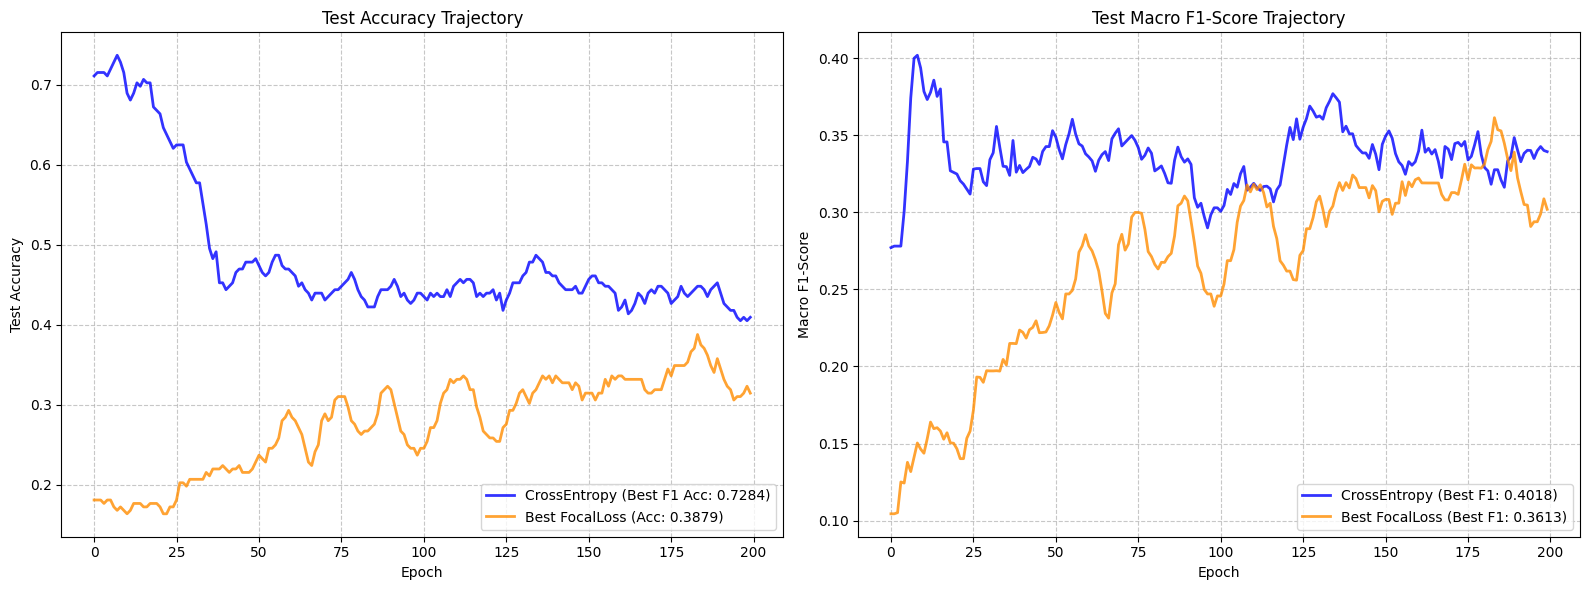

In [33]:
import copy
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score

def train_and_evaluate_advanced(criterion_to_use, num_epochs=200):
    """
    Trains a GAT model with given criterion and returns test accuracy
    and macro F1-score trajectories.
    """
    hidden_channels = 32
    out_channels = 16
    dropout_rate = 0.5
    lr = 0.005
    weight_decay = 0.0001

    model = CoregulationEdgeClassifier(
        in_channels=in_channels,
        hidden_channels=hidden_channels,
        out_channels=out_channels,
        edge_dim=num_edge_features,
        dropout=dropout_rate
    )
    edge_predictor = torch.nn.Linear(out_channels * 2, num_classes)

    optimizer = torch.optim.Adam(
        list(model.parameters()) + list(edge_predictor.parameters()),
        lr=lr,
        weight_decay=weight_decay
    )

    test_acc_history = []
    test_f1_history = []
    best_f1 = 0.0
    best_acc_at_best_f1 = 0.0

    for epoch in range(1, num_epochs + 1):
        model.train()
        edge_predictor.train()
        optimizer.zero_grad()

        node_embeddings = model(x_bio, edge_index, edge_attr)
        src = node_embeddings[edge_index[0]]
        dst = node_embeddings[edge_index[1]]

        edge_feats = F.dropout(torch.cat([src, dst], dim=-1), p=dropout_rate, training=True)
        out = edge_predictor(edge_feats)

        loss = criterion_to_use(out[train_mask], edge_labels[train_mask])
        loss.backward()
        optimizer.step()

        # Evaluate on Test Set
        model.eval()
        edge_predictor.eval()
        with torch.no_grad():
            node_embeddings = model(x_bio, edge_index, edge_attr)
            src = node_embeddings[edge_index[0]]
            dst = node_embeddings[edge_index[1]]
            edge_feats = torch.cat([src, dst], dim=-1)
            out = edge_predictor(edge_feats)

            pred = out[test_mask].argmax(dim=-1).cpu().numpy()
            true_labels = edge_labels[test_mask].cpu().numpy()

            # Calculate metrics
            acc = (pred == true_labels).mean()
            f1 = f1_score(true_labels, pred, average='macro', zero_division=0)

            test_acc_history.append(acc)
            test_f1_history.append(f1)

            if f1 > best_f1:
                best_f1 = f1
                best_acc_at_best_f1 = acc

    return test_acc_history, test_f1_history, best_acc_at_best_f1, best_f1

# --- Baseline: CrossEntropy ---
print("Training baseline model with Weighted CrossEntropyLoss...")
ce_criterion = torch.nn.CrossEntropyLoss(weight=class_weights_tensor)
ce_acc_hist, ce_f1_hist, ce_acc, ce_f1 = train_and_evaluate_advanced(ce_criterion)

# --- Tune FocalLoss ---
gammas = [0.5, 1.0, 2.0]
alphas = {
    'Weighted (Inverse Freq)': class_weights_tensor,
    'Unweighted': None
}

fl_results = {}
best_fl_config = None
best_fl_score = 0.0

print("\nTuning FocalLoss parameters...")
for alpha_name, alpha_tensor in alphas.items():
    for g in gammas:
        print(f"  Training FocalLoss (alpha={alpha_name}, gamma={g})...")
        focal_criterion = FocalLoss(alpha=alpha_tensor, gamma=g)
        results = train_and_evaluate_advanced(focal_criterion)
        fl_results[(alpha_name, g)] = results

        # Check if this is the best config based on F1-Score
        if results[3] > best_fl_score:
            best_fl_score = results[3]
            best_fl_config = (alpha_name, g)

print("\n" + "-" * 50)
print(f"Best CrossEntropy Macro F1: {ce_f1:.4f} (Acc: {ce_acc:.4f})")
print(f"Best FocalLoss Config: alpha={best_fl_config[0]}, gamma={best_fl_config[1]}")
print(f"Best FocalLoss Macro F1:    {best_fl_score:.4f} (Acc: {fl_results[best_fl_config][2]:.4f})")
print("-" * 50)

# --- Plotting the Trajectories ---
best_fl_acc_hist, best_fl_f1_hist, best_fl_acc, _ = fl_results[best_fl_config]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Accuracy
axes[0].plot(ce_acc_hist, label=f'CrossEntropy (Best F1 Acc: {ce_acc:.4f})', alpha=0.8, color='blue', linewidth=2)
axes[0].plot(best_fl_acc_hist, label=f'Best FocalLoss (Acc: {best_fl_acc:.4f})', alpha=0.8, color='darkorange', linewidth=2)
axes[0].set_title('Test Accuracy Trajectory')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Test Accuracy')
axes[0].legend(loc='lower right')
axes[0].grid(True, linestyle='--', alpha=0.7)

# Plot 2: Macro F1-Score
axes[1].plot(ce_f1_hist, label=f'CrossEntropy (Best F1: {ce_f1:.4f})', alpha=0.8, color='blue', linewidth=2)
axes[1].plot(best_fl_f1_hist, label=f'Best FocalLoss (Best F1: {best_fl_score:.4f})', alpha=0.8, color='darkorange', linewidth=2)
axes[1].set_title('Test Macro F1-Score Trajectory')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Macro F1-Score')
axes[1].legend(loc='lower right')
axes[1].grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

Re-training best FocalLoss model to extract test probabilities...


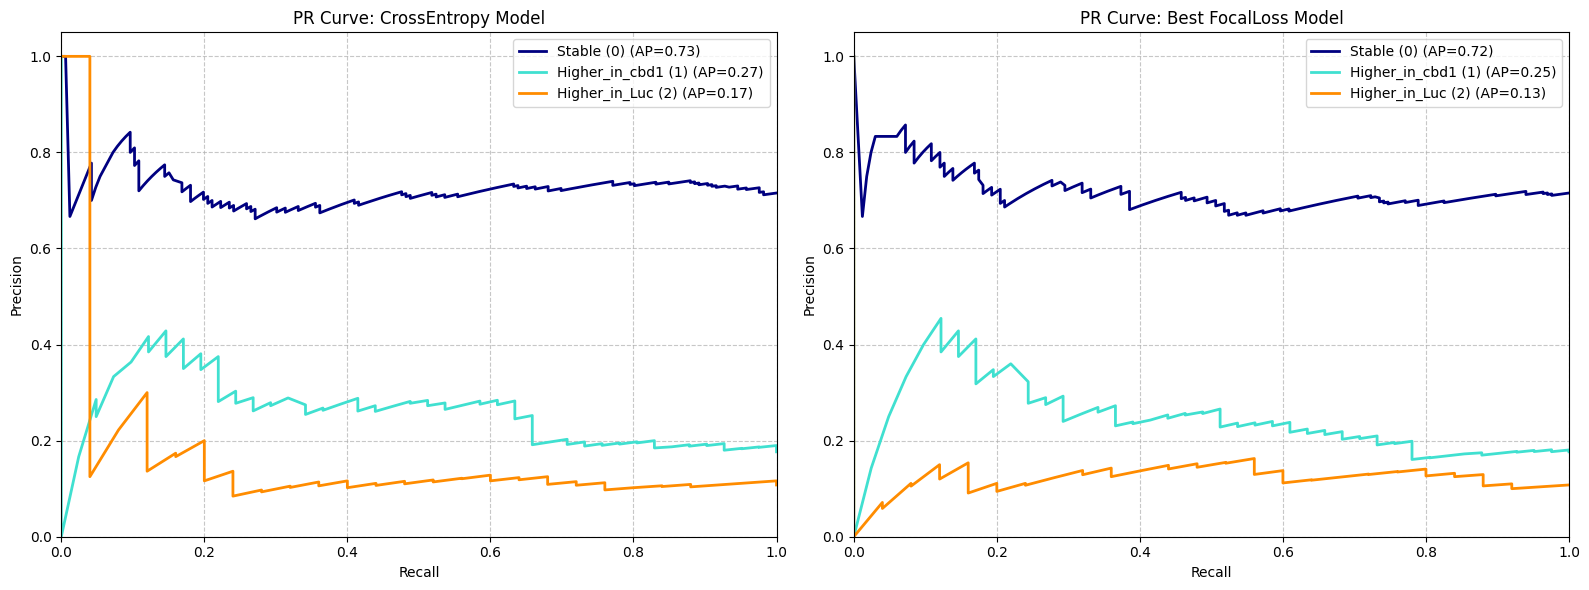

In [34]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score
from sklearn.preprocessing import label_binarize
import torch.nn.functional as F

# 1. Binarize labels for multi-class PR curves
y_test_true = edge_labels[test_mask].cpu().numpy()
y_test_bin = label_binarize(y_test_true, classes=[0, 1, 2])
n_classes = y_test_bin.shape[1]

# 2. Get probabilities from the tuned CrossEntropy model (final_model)
final_model.eval()
final_edge_predictor.eval()
with torch.no_grad():
    node_emb = final_model(x_bio, edge_index, edge_attr)
    src = node_emb[edge_index[0]]
    dst = node_emb[edge_index[1]]
    out_ce = final_edge_predictor(torch.cat([src, dst], dim=-1))
    y_score_ce = F.softmax(out_ce[test_mask], dim=-1).cpu().numpy()

# 3. Quickly retrain the best FocalLoss model (gamma=0.5, alpha=Weighted) to get its probabilities
print("Re-training best FocalLoss model to extract test probabilities...")
fl_model = CoregulationEdgeClassifier(in_channels=in_channels, hidden_channels=32, out_channels=16, edge_dim=num_edge_features, dropout=0.5)
fl_predictor = torch.nn.Linear(16 * 2, num_classes)
optimizer_fl = torch.optim.Adam(list(fl_model.parameters()) + list(fl_predictor.parameters()), lr=0.005, weight_decay=0.0001)
best_fl_criterion = FocalLoss(alpha=class_weights_tensor, gamma=0.5)

for epoch in range(1, 201):
    fl_model.train()
    fl_predictor.train()
    optimizer_fl.zero_grad()
    emb = fl_model(x_bio, edge_index, edge_attr)
    feats = F.dropout(torch.cat([emb[edge_index[0]], emb[edge_index[1]]], dim=-1), p=0.5, training=True)
    loss = best_fl_criterion(fl_predictor(feats)[train_mask], edge_labels[train_mask])
    loss.backward()
    optimizer_fl.step()

fl_model.eval()
fl_predictor.eval()
with torch.no_grad():
    emb = fl_model(x_bio, edge_index, edge_attr)
    out_fl = fl_predictor(torch.cat([emb[edge_index[0]], emb[edge_index[1]]], dim=-1))
    y_score_fl = F.softmax(out_fl[test_mask], dim=-1).cpu().numpy()

# 4. Plot the PR Curves
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
colors = ['navy', 'turquoise', 'darkorange']
class_names = ['Stable (0)', 'Higher_in_cbd1 (1)', 'Higher_in_Luc (2)']

def plot_pr_curve(ax, y_true, y_score, title):
    for i, color in zip(range(n_classes), colors):
        precision, recall, _ = precision_recall_curve(y_true[:, i], y_score[:, i])
        ap = average_precision_score(y_true[:, i], y_score[:, i])
        ax.plot(recall, precision, color=color, lw=2, label=f'{class_names[i]} (AP={ap:.2f})')
    ax.set_title(title)
    ax.set_xlabel('Recall')
    ax.set_ylabel('Precision')
    ax.set_xlim([0.0, 1.0])
    ax.set_ylim([0.0, 1.05])
    ax.legend(loc="upper right")
    ax.grid(True, linestyle='--', alpha=0.7)

plot_pr_curve(axes[0], y_test_bin, y_score_ce, 'PR Curve: CrossEntropy Model')
plot_pr_curve(axes[1], y_test_bin, y_score_fl, 'PR Curve: Best FocalLoss Model')

plt.tight_layout()
plt.show()


In [35]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

# 1. Reload the gene family annotations to ensure we have the mapping
fam_df = pd.read_csv('/content/annotations_with_gene_families.csv')
symbol_to_family = dict(zip(fam_df['Symbol'], fam_df['Description']))

# 2. Separate correctly classified test data for comparison
correctly_classified = test_data[test_data['Target_Rewiring_Label'] == test_data['Predicted_Label']]

# Helper function to extract families
def get_families(df):
    families = []
    for _, row in df.iterrows():
        f1 = symbol_to_family.get(row['Gene1_Symbol'], 'Unknown')
        f2 = symbol_to_family.get(row['Gene2_Symbol'], 'Unknown')
        # Add if valid and not unknown
        if pd.notna(f1) and str(f1).strip() not in ['Unknown', '']:
            families.append(str(f1).strip())
        if pd.notna(f2) and str(f2).strip() not in ['Unknown', '']:
            families.append(str(f2).strip())
    return families

# 3. Extract families
misclass_fams = get_families(misclassified)
correct_fams = get_families(correctly_classified)

# 4. Count frequencies
misclass_counts = Counter(misclass_fams)
correct_counts = Counter(correct_fams)

# 5. Get top 15 families in misclassified set
top_misclass = [f for f, c in misclass_counts.most_common(15)]

# Prepare data for comparison DataFrame
comp_data = []
for f in top_misclass:
    comp_data.append({
        'Gene Family / Description': f[:50] + '...' if len(f) > 50 else f, # Truncate long names for plotting
        'Misclassified': misclass_counts[f],
        'Correctly Classified': correct_counts[f]
    })

comp_df = pd.DataFrame(comp_data)
print("Top Gene Families in Misclassified Pairs:")
display(comp_df)


Top Gene Families in Misclassified Pairs:


,Gene Family / Description,Misclassified,Correctly Classified
0,Nuclear Hormone Receptor family,8,5
1,G-protein coupled receptors family 1 profile d...,5,16
2,UDP-glucuronosyltransferase,4,1
3,SCP domain-containing protein,4,2
4,Seven TM Receptor,4,2
5,Tyrosine-protein kinase,3,2
6,Protein kinase domain-containing protein,3,4
7,Major facilitator superfamily (MFS) profile do...,3,1
8,Uncharacterized protein,3,6
9,"DeHydrogenases, Short chain",3,0


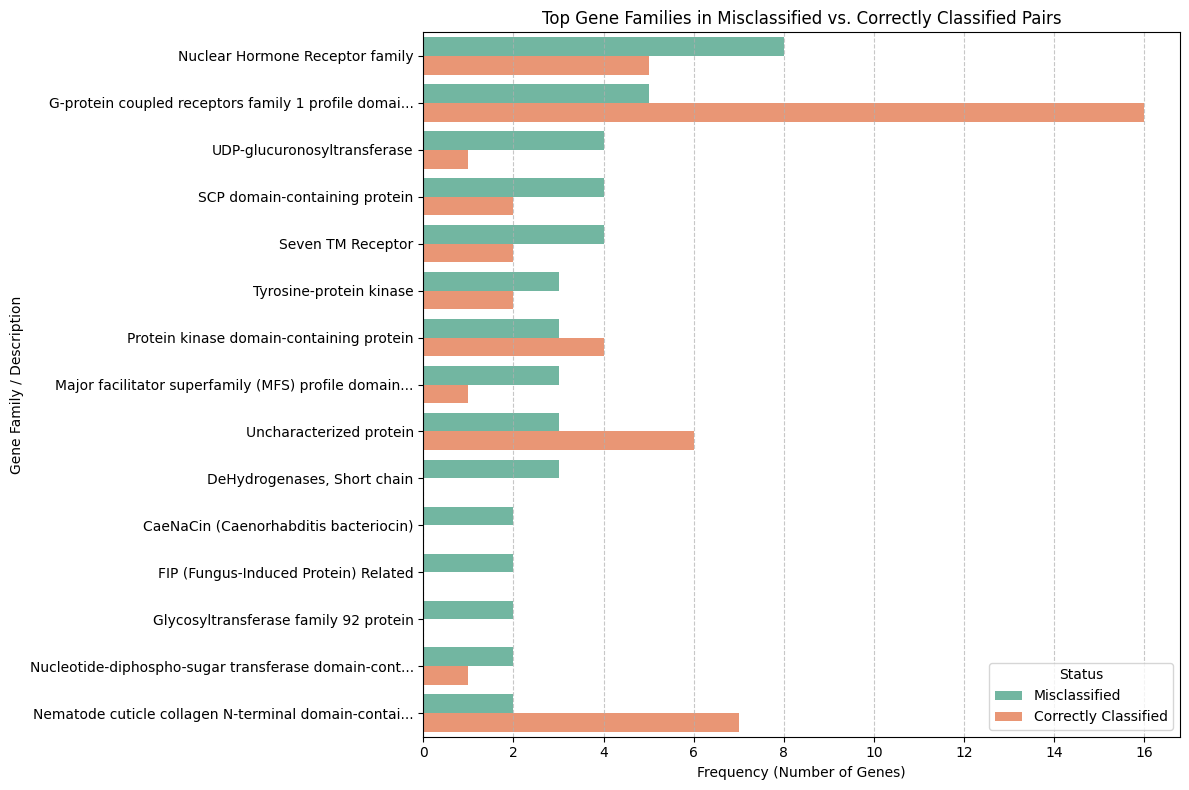

In [36]:
# 6. Visualize the comparison
comp_df_melted = comp_df.melt(id_vars='Gene Family / Description',
                              value_vars=['Misclassified', 'Correctly Classified'],
                              var_name='Classification Status', value_name='Frequency')

plt.figure(figsize=(12, 8))
sns.barplot(data=comp_df_melted, y='Gene Family / Description', x='Frequency', hue='Classification Status', palette='Set2')
plt.title('Top Gene Families in Misclassified vs. Correctly Classified Pairs')
plt.xlabel('Frequency (Number of Genes)')
plt.ylabel('Gene Family / Description')
plt.legend(title='Status')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


In [37]:
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
import numpy as np

# 1. Identify unique genes involved in misclassified pairs
misclass_genes = pd.unique(misclassified[['Gene1_ID', 'Gene2_ID']].values.ravel('K'))
misclass_indices = [gene_to_idx[g] for g in misclass_genes if g in gene_to_idx]

# Map to symbols and families
misclass_symbols = [gene_to_symbol.get(g, g) for g in misclass_genes if g in gene_to_idx]
misclass_fams = [symbol_to_family.get(s, 'Unknown') for s in misclass_symbols]

# 2. Extract their existing biological feature embeddings (from SVD)
X_misclass = node_features_reduced[misclass_indices]

# 3. Perform K-Means Clustering
num_clusters = 4 # Adjust this to find different granularities
kmeans = KMeans(n_clusters=num_clusters, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_misclass)

# 4. Create a DataFrame to analyze the contents of each cluster
cluster_df = pd.DataFrame({
    'Gene_ID': [misclass_genes[i] for i in range(len(misclass_indices))],
    'Symbol': misclass_symbols,
    'Family': misclass_fams,
    'Cluster': clusters
})

# Clean up families for display
cluster_df['Family'] = cluster_df['Family'].fillna('Unknown').astype(str)

print("--- Top Gene Families per Cluster ---")
for c in range(num_clusters):
    print(f"\nCluster {c} (Total genes: {sum(clusters == c)}):")
    # Filter out 'Unknown' or empty string for a cleaner view
    valid_fams = cluster_df[(cluster_df['Cluster'] == c) & (~cluster_df['Family'].isin(['Unknown', '', 'nan']))]
    top_fams = valid_fams['Family'].value_counts().head(5)
    if len(top_fams) > 0:
        display(top_fams.to_frame(name='Count'))
    else:
        print("Mostly Uncharacterized or Unknown.")


--- Top Gene Families per Cluster ---

Cluster 0 (Total genes: 110):


,Count
Family,
G-protein coupled receptors family 1 profile domain-containing protein,5
UDP-glucuronosyltransferase,4
Tyrosine-protein kinase,3
"DeHydrogenases, Short chain",3
Uncharacterized protein,3



Cluster 1 (Total genes: 12):


,Count
Family,
Nuclear Hormone Receptor family,8
NR LBD domain-containing protein;Nuclear Hormone Receptor family,2
Nuclear receptor domain-containing protein,2



Cluster 2 (Total genes: 4):


,Count
Family,
Seven TM Receptor,4



Cluster 3 (Total genes: 4):


,Count
Family,
SCP domain-containing protein,4


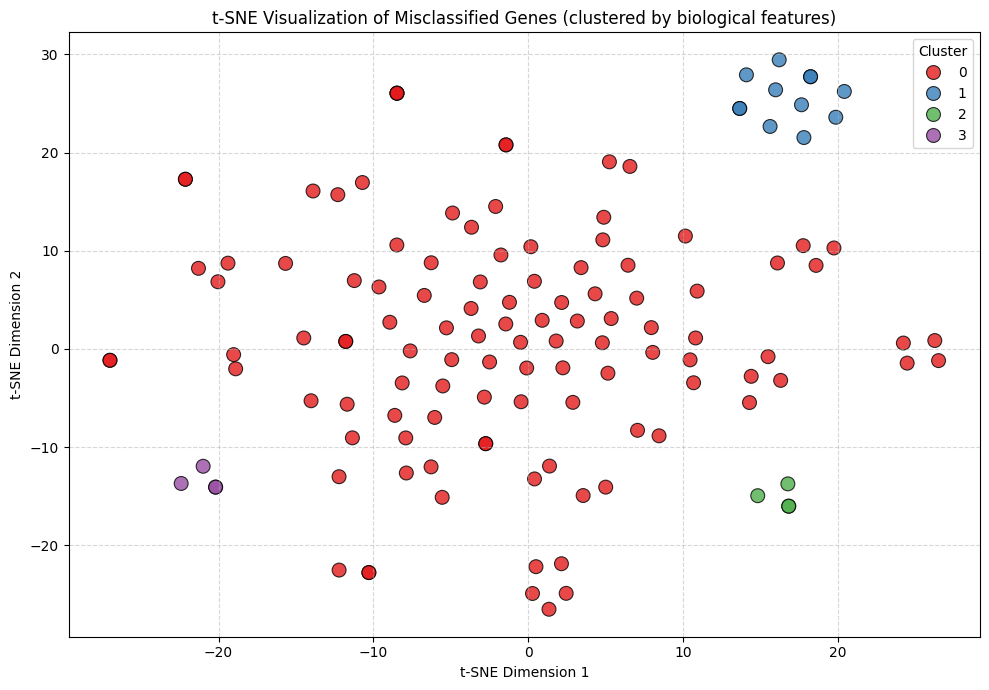

In [38]:
# 5. Visualize the Clusters using t-SNE
# Adjust perplexity based on the small sample size of misclassified genes
perplexity_value = min(30, len(X_misclass) - 1)
tsne = TSNE(n_components=2, random_state=42, perplexity=perplexity_value)
X_tsne = tsne.fit_transform(X_misclass)

plt.figure(figsize=(10, 7))
sns.scatterplot(
    x=X_tsne[:, 0], y=X_tsne[:, 1],
    hue=clusters,
    palette=sns.color_palette('Set1', num_clusters),
    s=100, alpha=0.8, edgecolor='k'
)

plt.title('t-SNE Visualization of Misclassified Genes (clustered by biological features)')
plt.xlabel('t-SNE Dimension 1')
plt.ylabel('t-SNE Dimension 2')
plt.legend(title='Cluster')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


**Cluster Analysis Insights:**
By embedding the functional annotations (GO terms + families) of the genes involved in our model's errors and clustering them, we can see if errors isolate into distinct biological "pockets". For example, one cluster might represent metabolic pathways (like UDP-glucuronosyltransferase) while another isolates signaling receptors (like G-protein or Nuclear Hormone receptors). This tells us if our model is systematically failing on certain sub-graphs of biological function.

**Analysis:**
The bar chart above compares the raw frequencies of gene families present in the misclassified gene pairs versus those in the correctly classified pairs. By looking at families with high misclassification counts relative to their correct counts, you can pinpoint biological functions or structural families that the GNN model struggles to predict accurately.

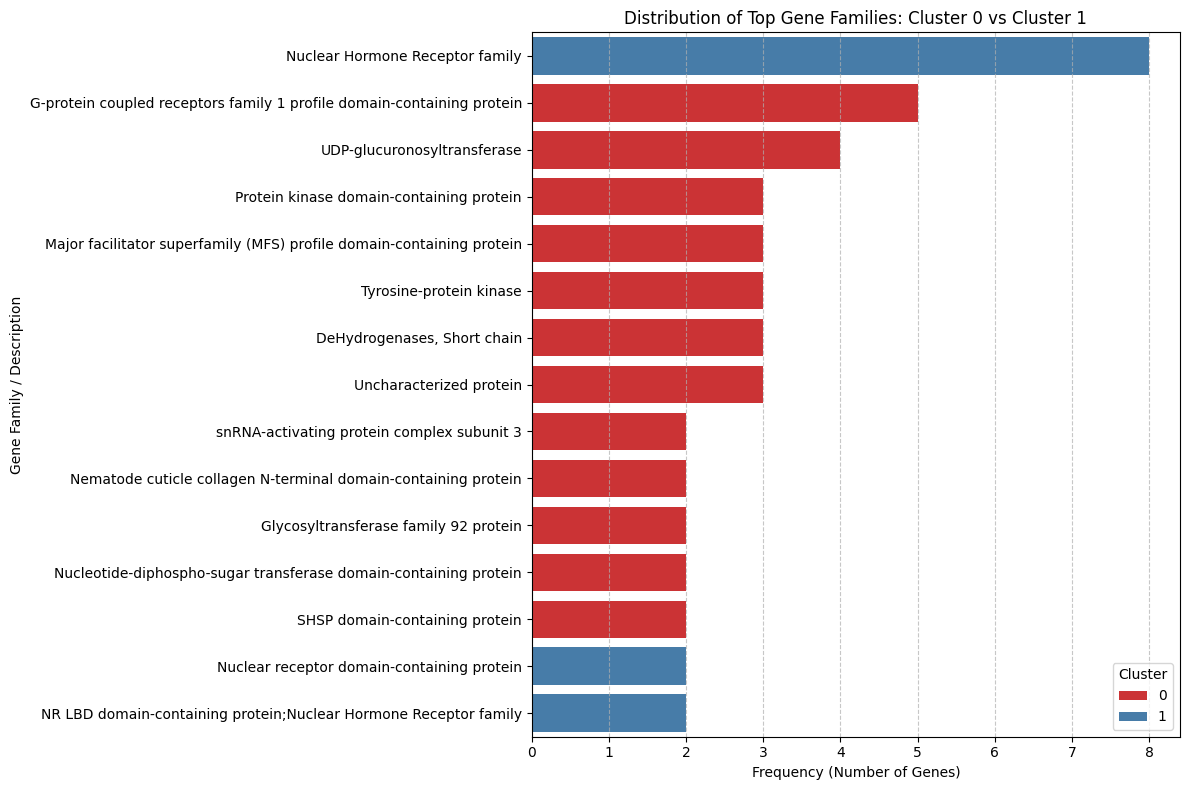

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Filter for Clusters 0 and 1, excluding 'Unknown' or uncharacterized families
c0_c1_df = cluster_df[(cluster_df['Cluster'].isin([0, 1])) & (~cluster_df['Family'].isin(['Unknown', '', 'nan']))].copy()

# Identify the top 15 most frequent families across these two clusters for a clean plot
top_families = c0_c1_df['Family'].value_counts().head(15).index

# Filter data to only include these top families
plot_data = c0_c1_df[c0_c1_df['Family'].isin(top_families)]

# Create a count plot to compare distributions
plt.figure(figsize=(12, 8))
sns.countplot(
    data=plot_data,
    y='Family',
    hue='Cluster',
    order=top_families,
    palette={0: sns.color_palette('Set1')[0], 1: sns.color_palette('Set1')[1]}
)
plt.title('Distribution of Top Gene Families: Cluster 0 vs Cluster 1')
plt.xlabel('Frequency (Number of Genes)')
plt.ylabel('Gene Family / Description')
plt.legend(title='Cluster', loc='lower right')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


--- Top 15 GO Terms for Cluster 0 ---


,GO_Term,Frequency,Cluster
0,GO:0016020,69,Cluster 0
1,GO:0005634,48,Cluster 0
2,GO:0005524,32,Cluster 0
3,GO:0005737,32,Cluster 0
4,GO:0004674,18,Cluster 0
5,GO:0005886,16,Cluster 0
6,GO:0006468,13,Cluster 0
7,GO:0004672,12,Cluster 0
8,GO:0004713,12,Cluster 0
9,GO:0046872,12,Cluster 0



--- Top 15 GO Terms for Cluster 1 ---


,GO_Term,Frequency,Cluster
0,GO:0005634,19,Cluster 1
1,GO:0003677,12,Cluster 1
2,GO:0003700,12,Cluster 1
3,GO:0006355,12,Cluster 1
4,GO:0008270,12,Cluster 1
5,GO:0043565,12,Cluster 1
6,GO:0046872,12,Cluster 1
7,GO:0045087,2,Cluster 1


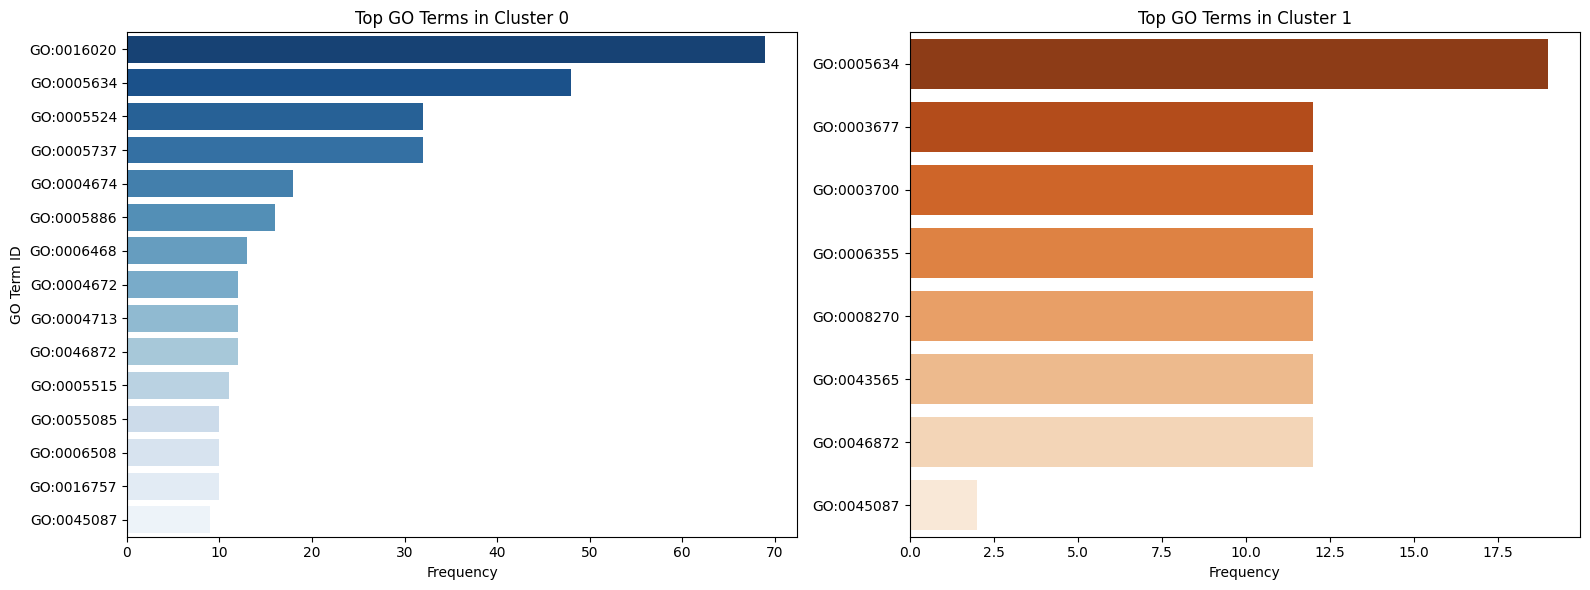

In [40]:
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Extract Gene IDs for Cluster 0 and Cluster 1
c0_genes = cluster_df[cluster_df['Cluster'] == 0]['Gene_ID'].tolist()
c1_genes = cluster_df[cluster_df['Cluster'] == 1]['Gene_ID'].tolist()

# Get GO terms for each cluster
c0_go_terms = []
for g in c0_genes:
    c0_go_terms.extend(gene_to_go.get(g, []))

c1_go_terms = []
for g in c1_genes:
    c1_go_terms.extend(gene_to_go.get(g, []))

# Count frequencies
c0_go_counts = Counter(c0_go_terms)
c1_go_counts = Counter(c1_go_terms)

# Get Top 15 for each
top_c0 = pd.DataFrame(c0_go_counts.most_common(15), columns=['GO_Term', 'Frequency'])
top_c0['Cluster'] = 'Cluster 0'

top_c1 = pd.DataFrame(c1_go_counts.most_common(15), columns=['GO_Term', 'Frequency'])
top_c1['Cluster'] = 'Cluster 1'

# Display dataframes
print("--- Top 15 GO Terms for Cluster 0 ---")
display(top_c0)

print("\n--- Top 15 GO Terms for Cluster 1 ---")
display(top_c1)

# Plotting the comparison
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(data=top_c0, y='GO_Term', x='Frequency', ax=axes[0], hue='GO_Term', palette='Blues_r', legend=False)
axes[0].set_title('Top GO Terms in Cluster 0')
axes[0].set_xlabel('Frequency')
axes[0].set_ylabel('GO Term ID')

sns.barplot(data=top_c1, y='GO_Term', x='Frequency', ax=axes[1], hue='GO_Term', palette='Oranges_r', legend=False)
axes[1].set_title('Top GO Terms in Cluster 1')
axes[1].set_xlabel('Frequency')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()


Number of NHR-involved pairs: 45
Number of Non-NHR pairs: 1110

--- Variance of Co-expression (NHR vs Non-NHR) ---


,NHR Pairs Variance,Non-NHR Pairs Variance
Target_Comp_PCC,0.163054,0.212324
Target_Luc_PCC,0.242502,0.326891
Target_cbd1_PCC,0.269474,0.322252


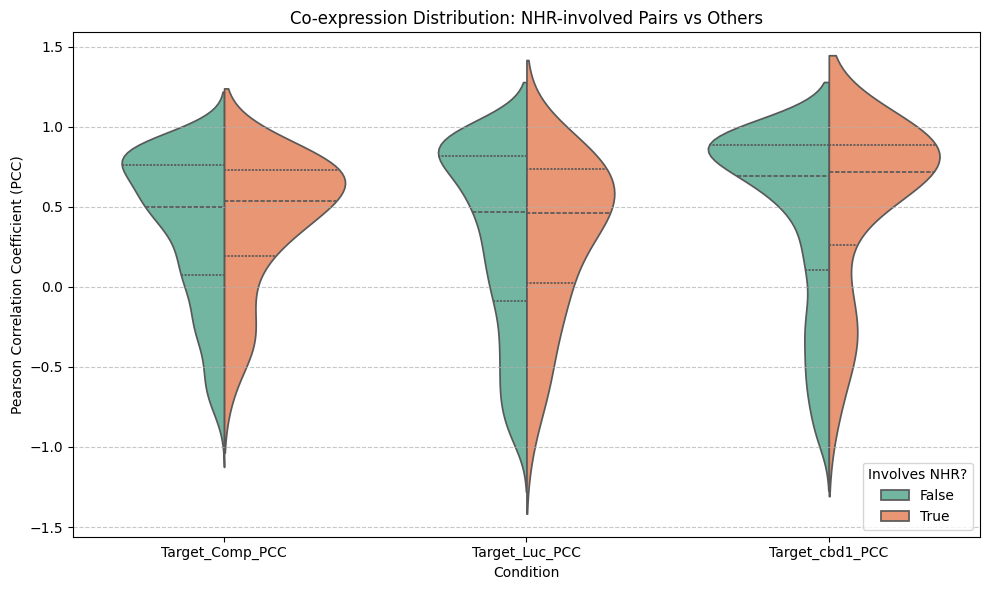

In [41]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Helper function to check if a pair involves a Nuclear Hormone Receptor
def is_nhr_pair(row):
    fam1 = symbol_to_family.get(row['Gene1_Symbol'], 'Unknown')
    fam2 = symbol_to_family.get(row['Gene2_Symbol'], 'Unknown')
    return (fam1 == 'Nuclear Hormone Receptor family') or (fam2 == 'Nuclear Hormone Receptor family')

# Flag pairs involving at least one NHR
data['Is_NHR_Pair'] = data.apply(is_nhr_pair, axis=1)

nhr_data = data[data['Is_NHR_Pair']]
non_nhr_data = data[~data['Is_NHR_Pair']]

print(f"Number of NHR-involved pairs: {len(nhr_data)}")
print(f"Number of Non-NHR pairs: {len(non_nhr_data)}")

# Analyze variance in co-expression across conditions
coexpr_cols = ['Target_Comp_PCC', 'Target_Luc_PCC', 'Target_cbd1_PCC']

print("\n--- Variance of Co-expression (NHR vs Non-NHR) ---")
variance_df = pd.DataFrame({
    'NHR Pairs Variance': nhr_data[coexpr_cols].var(),
    'Non-NHR Pairs Variance': non_nhr_data[coexpr_cols].var()
})
display(variance_df)

# Prepare data for visualization
plot_data = data.melt(id_vars=['Pair_ID', 'Is_NHR_Pair'], value_vars=coexpr_cols,
                      var_name='Condition', value_name='PCC')

# Visualize the distribution
plt.figure(figsize=(10, 6))
sns.violinplot(data=plot_data, x='Condition', y='PCC', hue='Is_NHR_Pair', split=True, inner="quartile", palette="Set2")
plt.title('Co-expression Distribution: NHR-involved Pairs vs Others')
plt.xlabel('Condition')
plt.ylabel('Pearson Correlation Coefficient (PCC)')
plt.legend(title='Involves NHR?', loc='lower right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [44]:
from sklearn.metrics import classification_report

# 1. Get predictions for all edges
final_model.eval()
final_edge_predictor.eval()
with torch.no_grad():
    node_emb = final_model(x_bio, edge_index, edge_attr)
    out = final_edge_predictor(torch.cat([node_emb[edge_index[0]], node_emb[edge_index[1]]], dim=-1))
    preds = out.argmax(dim=-1).cpu().numpy()

# 2. Split test set into NHR and Non-NHR groups
test_indices = test_mask.nonzero(as_tuple=True)[0].cpu().numpy()
preds_test = preds[test_indices]

is_nhr_test = data.iloc[test_indices]['Is_NHR_Pair'].values
true_labels = edge_labels[test_mask].cpu().numpy()

test_preds_nhr = preds_test[is_nhr_test]
test_true_nhr = true_labels[is_nhr_test]

test_preds_non_nhr = preds_test[~is_nhr_test]
test_true_non_nhr = true_labels[~is_nhr_test]

print("=== Model Performance on NHR Pairs (Test Set) ===")
if len(test_true_nhr) > 0:
    print(classification_report(test_true_nhr, test_preds_nhr, target_names=labels_order, labels=[0, 1, 2], zero_division=0))
else:
    print("No NHR pairs present in the test set.")

print("\n=== Model Performance on Non-NHR Pairs (Test Set) ===")
print(classification_report(test_true_non_nhr, test_preds_non_nhr, target_names=labels_order, labels=[0, 1, 2], zero_division=0))


=== Model Performance on NHR Pairs (Test Set) ===
                precision    recall  f1-score   support

        Stable       0.33      1.00      0.50         3
Higher_in_cbd1       0.00      0.00      0.00         4
 Higher_in_Luc       0.00      0.00      0.00         2

      accuracy                           0.33         9
     macro avg       0.11      0.33      0.17         9
  weighted avg       0.11      0.33      0.17         9


=== Model Performance on Non-NHR Pairs (Test Set) ===
                precision    recall  f1-score   support

        Stable       0.75      0.96      0.84       163
Higher_in_cbd1       0.67      0.11      0.19        37
 Higher_in_Luc       0.43      0.13      0.20        23

      accuracy                           0.74       223
     macro avg       0.61      0.40      0.41       223
  weighted avg       0.70      0.74      0.67       223



Extracting GNN Attention Weights for NHR Pairs...


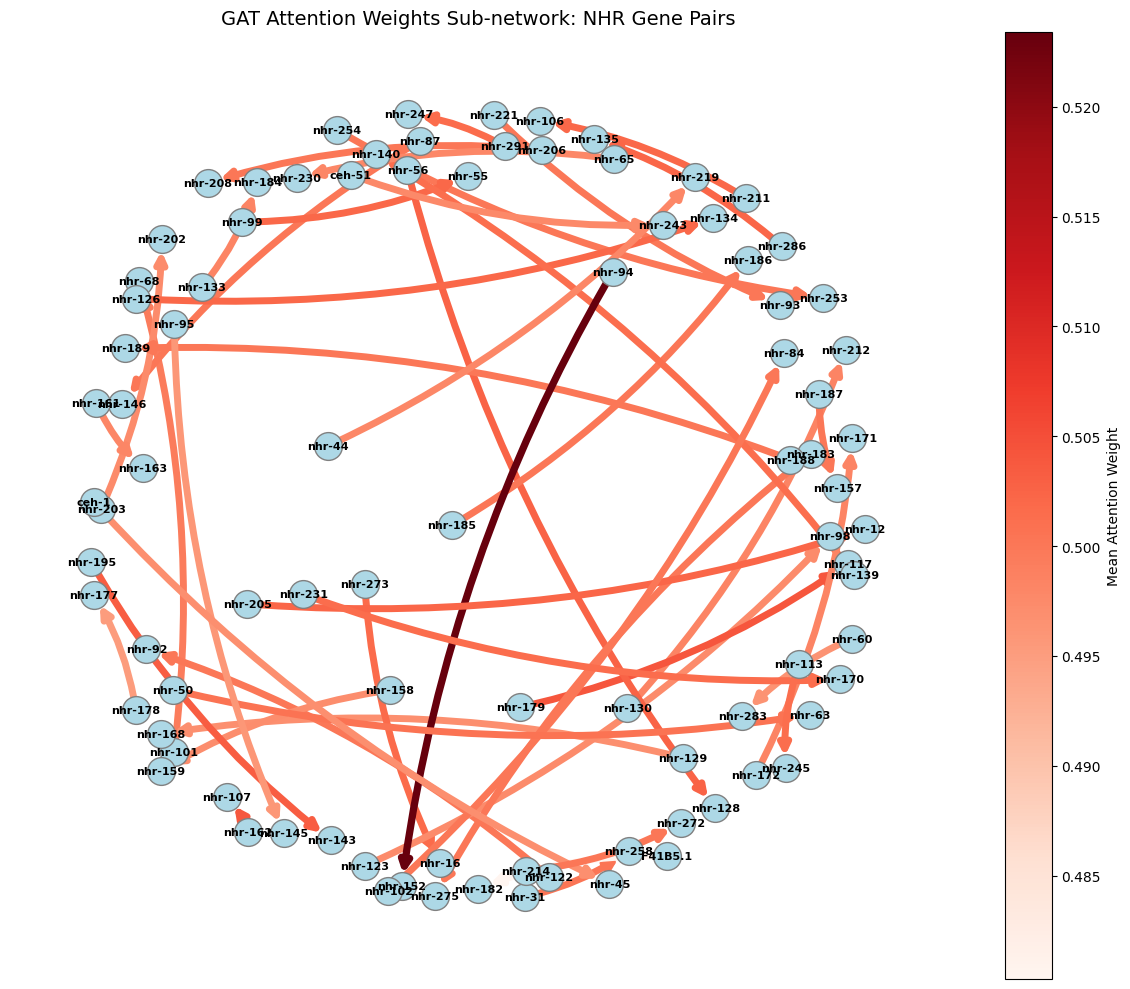

In [45]:
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib as mpl

print("Extracting GNN Attention Weights for NHR Pairs...")

# Extract attention weights from the first layer of the final model
final_model.eval()
with torch.no_grad():
    _, attn_edge_index, attn_weights = final_model(x_bio, edge_index, edge_attr, return_attention_weights=True)

# Average attention across heads if multiple heads exist (GAT normally returns multi-head attention)
if attn_weights.dim() > 1:
    attn_weights_mean = attn_weights.mean(dim=-1)
else:
    attn_weights_mean = attn_weights

# Map attention weights to a dictionary for quick lookup
attn_dict = {}
for i in range(attn_edge_index.shape[1]):
    u, v = attn_edge_index[0, i].item(), attn_edge_index[1, i].item()
    attn_dict[(u, v)] = attn_weights_mean[i].item()

# Get the source and target nodes specifically for NHR pairs in our dataset
nhr_edge_mask = data['Is_NHR_Pair'].values
nhr_edges = edge_index[:, nhr_edge_mask]
nhr_source = nhr_edges[0].cpu().numpy()
nhr_target = nhr_edges[1].cpu().numpy()

# Build a directed graph for visualization
G = nx.DiGraph()
edge_colors = []
edge_widths = []

for u, v in zip(nhr_source, nhr_target):
    # GAT adds self-loops, but we just look up the original edge directions
    weight = attn_dict.get((u, v), 0.0)
    G.add_edge(u, v, weight=weight)
    edge_widths.append(weight * 10)  # Scale width for visual clarity
    edge_colors.append(weight)

# Draw the graph
plt.figure(figsize=(12, 10))
pos = nx.spring_layout(G, k=0.8, seed=42)

# Draw nodes
nx.draw_networkx_nodes(G, pos, node_size=400, node_color='lightblue', edgecolors='gray')

# Draw edges with color mapping based on attention weight
edges = nx.draw_networkx_edges(
    G, pos,
    edge_color=edge_colors,
    width=edge_widths,
    edge_cmap=plt.cm.Reds,
    arrows=True,
    arrowsize=15,
    connectionstyle="arc3,rad=0.1"
)

# Add Gene Symbol labels to the nodes
labels = {n: gene_to_symbol.get(unique_genes[n], str(n)) for n in G.nodes()}
nx.draw_networkx_labels(G, pos, labels, font_size=8, font_weight='bold')

plt.title("GAT Attention Weights Sub-network: NHR Gene Pairs", fontsize=14)
if edge_colors:
    sm = mpl.cm.ScalarMappable(cmap=plt.cm.Reds, norm=mpl.colors.Normalize(vmin=min(edge_colors), vmax=max(edge_colors)))
    sm.set_array([])
    plt.colorbar(sm, ax=plt.gca(), label="Mean Attention Weight")
plt.axis('off')
plt.tight_layout()
plt.show()


In [46]:
!pip install xlrd openpyxl -q

import pandas as pd

new_annotation_files = [
    '/content/ABCtransporter.xls',
    '/content/chemosensory gene clusters.xls',
    '/content/GeneSetsAtFourLevels_WBID.xls',
    '/content/9_24GenomeCelMasterSpreedsheetcel6239genomeannotation_family.xlsx'
]

for file_path in new_annotation_files:
    print(f"\n{'='*60}")
    print(f"Inspecting: {file_path}")
    print(f"{'='*60}")
    try:
        # Read the excel file
        df = pd.read_excel(file_path)
        print("Columns:", df.columns.tolist())
        print(f"Total Rows: {len(df)}")
        display(df.head(3))
    except Exception as e:
        print(f"Error reading {file_path}: {e}")



Inspecting: /content/ABCtransporter.xls
Columns: ['clusterid', 'clustersize', 'species', 'accession', 'geneclass', 'abc_family (C. elegans)']
Total Rows: 412


,clusterid,clustersize,species,accession,geneclass,abc_family (C. elegans)
0,46,157,Caenorhabditis brenneri,CBN23436,NaN,NaN
1,46,157,Caenorhabditis brenneri,CBN13139,haf,NaN
2,46,157,Caenorhabditis brenneri,CBN31144,NaN,NaN



Inspecting: /content/chemosensory gene clusters.xls
Columns: ['clusterid', 'clustersize', 'species', 'accession', 'geneclass']
Total Rows: 8134


,clusterid,clustersize,species,accession,geneclass
0,207,86,Caenorhabditis japonica,CJA04195,srg
1,207,86,Caenorhabditis brenneri,CBN30978,NaN
2,207,86,Caenorhabditis elegans,C51F7.2,srg



Inspecting: /content/GeneSetsAtFourLevels_WBID.xls
Columns: ['AMINO ACIDS', 'WBGene00000107;WBGene00000108;WBGene00000110;WBGene00000111;WBGene00000112;WBGene00000113;WBGene00000114;WBGene00000115;WBGene00000117;WBGene00000118;WBGene00000138;WBGene00000181;WBGene00000239;WBGene00000240;WBGene00000296;WBGene00000775;WBGene00000800;WBGene00000830;WBGene00000831;WBGene00001077;WBGene00001149;WBGene00001150;WBGene00001152;WBGene00001154;WBGene00001155;WBGene00001156;WBGene00001157;WBGene00001158;WBGene00001527;WBGene00001602;WBGene00001603;WBGene00001604;WBGene00001606;WBGene00001607;WBGene00001790;WBGene00001791;WBGene00001794;WBGene00001839;WBGene00001843;WBGene00001993;WBGene00002249;WBGene00002250;WBGene00003162;WBGene00003214;WBGene00003234;WBGene00003816;WBGene00003844;WBGene00003960;WBGene00004025;WBGene00004026;WBGene00004259;WBGene00004875;WBGene00006416;WBGene00006518;WBGene00006541;WBGene00006562;WBGene00006600;WBGene00006762;WBGene00007122;WBGene00007129;WBGene00007197;WBGene0

,AMINO ACIDS,WBGene00000107;WBGene00000108;WBGene00000110;WBGene00000111;WBGene00000112;WBGene00000113;WBGene00000114;WBGene00000115;WBGene00000117;WBGene00000118;WBGene00000138;WBGene00000181;WBGene00000239;WBGene00000240;WBGene00000296;WBGene00000775;WBGene00000800;WBGene00000830;WBGene00000831;WBGene00001077;WBGene00001149;WBGene00001150;WBGene00001152;WBGene00001154;WBGene00001155;WBGene00001156;WBGene00001157;WBGene00001158;WBGene00001527;WBGene00001602;WBGene00001603;WBGene00001604;WBGene00001606;WBGene00001607;WBGene00001790;WBGene00001791;WBGene00001794;WBGene00001839;WBGene00001843;WBGene00001993;WBGene00002249;WBGene00002250;WBGene00003162;WBGene00003214;WBGene00003234;WBGene00003816;WBGene00003844;WBGene00003960;WBGene00004025;WBGene00004026;WBGene00004259;WBGene00004875;WBGene00006416;WBGene00006518;WBGene00006541;WBGene00006562;WBGene00006600;WBGene00006762;WBGene00007122;WBGene00007129;WBGene00007197;WBGene00007236;WBGene00007480;WBGene00007507;WBGene00007508;WBGene00007509;WBGene00007533;WBGene00007653;WBGene00007756;WBGene00007836;WBGene00008127;WBGene00008205;WBGene00008354;WBGene00008408;WBGene00008409;WBGene00008435;WBGene00008490;WBGene00008514;WBGene00008546;WBGene00008732;WBGene00009001;WBGene00009035;WBGene00009048;WBGene00009177;WBGene00009232;WBGene00009271;WBGene00009319;WBGene00009628;WBGene00009636;WBGene00009706;WBGene00009813;WBGene00009918;WBGene00009952;WBGene00010035;WBGene00010052;WBGene00010286;WBGene00010380;WBGene00010383;WBGene00010456;WBGene00010595;WBGene00010661;WBGene00010759;WBGene00010794;WBGene00010924;WBGene00010941;WBGene00011064;WBGene00011088;WBGene00011089;WBGene00011291;WBGene00011307;WBGene00011587;WBGene00011767;WBGene00011932;WBGene00011938;WBGene00012007;WBGene00012326;WBGene00012713;WBGene00012799;WBGene00012815;WBGene00012855;WBGene00012909;WBGene00013103;WBGene00013220;WBGene00013379;WBGene00013866;WBGene00013870;WBGene00013894;WBGene00013920;WBGene00014054;WBGene00014095;WBGene00014098;WBGene00015021;WBGene00015064;WBGene00015125;WBGene00015326;WBGene00015332;WBGene00015334;WBGene00015509;WBGene00015538;WBGene00015540;WBGene00015733;WBGene00015773;WBGene00015778;WBGene00015802;WBGene00015814;WBGene00015894;WBGene00016020;WBGene00016201;WBGene00016294;WBGene00016333;WBGene00016419;WBGene00016509;WBGene00016629;WBGene00016652;WBGene00016657;WBGene00016943;WBGene00017051;WBGene00017084;WBGene00017262;WBGene00017301;WBGene00017387;WBGene00017442;WBGene00017565;WBGene00017648;WBGene00017765;WBGene00017874;WBGene00017975;WBGene00018174;WBGene00018357;WBGene00018398;WBGene00018491;WBGene00018764;WBGene00018783;WBGene00018904;WBGene00018986;WBGene00019094;WBGene00019096;WBGene00019406;WBGene00019433;WBGene00019620;WBGene00019633;WBGene00019730;WBGene00019819;WBGene00019962;WBGene00019978;WBGene00020022;WBGene00020146;WBGene00020149;WBGene00020347;WBGene00020366;WBGene00020382;WBGene00020436;WBGene00020658;WBGene00020679;WBGene00020797;WBGene00020812;WBGene00020842;WBGene00020950;WBGene00021128;WBGene00021401;WBGene00021553;WBGene00021787;WBGene00021817;WBGene00022006;WBGene00022007;WBGene00022076;WBGene00022104;WBGene00022150;WBGene00022231;WBGene00022856;WBGene00077688
0,CARBOHYDRATES,WBGene00000107;WBGene00000108;WBGene00000110;W...
1,COFACTORS AND VITAMINS,WBGene00000240;WBGene00000296;WBGene00000298;W...
2,ENERGY,WBGene00000040;WBGene00000041;WBGene00000206;W...



Inspecting: /content/9_24GenomeCelMasterSpreedsheetcel6239genomeannotation_family.xlsx
Columns: ['NCBI GeneID', 'Symbol', 'Description', 'Gene Type', 'Transcripts', 'Chromosomes', 'Nomenclature ID', 'Annotation Genomic Range Accession ', 'Annotation Genomic Range Start', 'Annotation Genomic Range Stop', 'Orientation', 'Proteins']
Total Rows: 46927


,NCBI GeneID,Symbol,Description,Gene Type,Transcripts,Chromosomes,Nomenclature ID,Annotation Genomic Range Accession,Annotation Genomic Range Start,Annotation Genomic Range Stop,Orientation,Proteins
0,172981,daf-16,Fork-head domain-containing protein;Forkhead b...,PROTEIN_CODING,11.0,I,WBGene00000912,NC_003279.8,10750498,10776703,plus,11.0
1,259839,unc-54,Myosin-4,PROTEIN_CODING,1.0,I,WBGene00006789,NC_003279.8,14855901,14863482,minus,1.0
2,173078,hsf-1,Heat shock transcription factor hsf-1,PROTEIN_CODING,1.0,I,WBGene00002004,NC_003279.8,11953509,11961984,minus,1.0


In [47]:
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
import torch

# Create a reverse mapping from Symbol to WBGene ID
symbol_to_wbgene = {v: k for k, v in gene_to_symbol.items()}

# Dictionary to hold new annotations for each WBGene ID
gene_extra_annotations = {g: [] for g in unique_genes}

# 1. Parse GeneSets (WBGene IDs)
try:
    df_gs = pd.read_excel('/content/GeneSetsAtFourLevels_WBID.xls', header=None)
    for _, row in df_gs.iterrows():
        category = str(row[0])
        wbgene_str = str(row[1])
        if pd.notna(wbgene_str):
            for wbgene in wbgene_str.split(';'):
                wbgene = wbgene.strip()
                if wbgene in gene_extra_annotations:
                    # Add the category as a tag (replace spaces to keep it as a single token)
                    gene_extra_annotations[wbgene].append(category.replace(' ', '_'))
    print("Successfully parsed GeneSets.")
except Exception as e:
    print(f"Error parsing GeneSets: {e}")

# 2. Parse ABC Transporters
try:
    df_abc = pd.read_excel('/content/ABCtransporter.xls')
    for _, row in df_abc.iterrows():
        sym = str(row.get('geneclass', ''))
        acc = str(row.get('accession', ''))
        abc_fam = str(row.get('abc_family (C. elegans)', ''))

        # Map by symbol or accession
        target_id = symbol_to_wbgene.get(sym) or symbol_to_wbgene.get(acc)
        if target_id and target_id in gene_extra_annotations and abc_fam != 'nan':
            gene_extra_annotations[target_id].append(f"ABC_Family_{abc_fam.replace(' ', '_')}")
    print("Successfully parsed ABC Transporters.")
except Exception as e:
    print(f"Error parsing ABC transporters: {e}")

# 3. Parse Chemosensory Clusters
try:
    df_chemo = pd.read_excel('/content/chemosensory gene clusters.xls')
    for _, row in df_chemo.iterrows():
        sym = str(row.get('geneclass', ''))
        acc = str(row.get('accession', ''))

        target_id = symbol_to_wbgene.get(sym) or symbol_to_wbgene.get(acc)
        if target_id and target_id in gene_extra_annotations:
            gene_extra_annotations[target_id].append("Chemosensory_Cluster")
    print("Successfully parsed Chemosensory Clusters.")
except Exception as e:
    print(f"Error parsing Chemosensory: {e}")

# 4. Master Spreadsheet
try:
    df_master = pd.read_excel('/content/9_24GenomeCelMasterSpreedsheetcel6239genomeannotation_family.xlsx')
    fam_col = [c for c in df_master.columns if 'family' in str(c).lower()]
    if fam_col:
        fam_col = fam_col[0]
        for _, row in df_master.iterrows():
            sym = str(row.get('Symbol', ''))
            fam = str(row.get(fam_col, ''))
            target_id = symbol_to_wbgene.get(sym)
            if target_id and target_id in gene_extra_annotations and fam != 'nan':
                gene_extra_annotations[target_id].append(fam.replace(' ', '_'))
    print("Successfully parsed Master Spreadsheet.")
except Exception as e:
    print(f"Error parsing Master Spreadsheet: {e}")

# 5. Rebuild gene_docs with the newly extracted features
new_gene_docs = []
for gene_id in unique_genes:
    # Original features
    go_terms_str = " ".join(gene_to_go.get(gene_id, []))
    symbol = gene_to_symbol.get(gene_id, "")
    desc = symbol_to_desc.get(symbol, "")

    # New features
    extra_feats = " ".join(gene_extra_annotations.get(gene_id, []))

    # Combine everything
    doc = f"{go_terms_str} {desc} {extra_feats}"
    new_gene_docs.append(doc)

# 6. Re-vectorize and reduce using TF-IDF and SVD
print("\nRe-computing TF-IDF and SVD...")
vectorizer = TfidfVectorizer(max_features=5000)
tfidf_matrix = vectorizer.fit_transform(new_gene_docs)

n_components = 64
svd = TruncatedSVD(n_components=n_components, random_state=42)
node_features_reduced_new = svd.fit_transform(tfidf_matrix)

# Update x_bio
x_bio = torch.tensor(node_features_reduced_new, dtype=torch.float)
print(f"Updated Biological Node Features shape: {x_bio.shape}")

# Print a sample of the first document to verify the text composition
print("\nSample Document 0:")
print(new_gene_docs[0][:200] + "...")

Successfully parsed GeneSets.
Successfully parsed ABC Transporters.
Successfully parsed Chemosensory Clusters.
Successfully parsed Master Spreadsheet.

Re-computing TF-IDF and SVD...
Updated Biological Node Features shape: torch.Size([2310, 64])

Sample Document 0:
GO:0004672 GO:0004674 GO:0004674 GO:0005524 GO:0005524 GO:0005634 GO:0005634 GO:0005634 GO:0005737 GO:0005737 GO:0006468 GO:0008340 GO:0008340 GO:0035095 GO:0035095 GO:0046872 GO:0060625 GO:0106310 GO...


### Retrain Model with Enriched Features
Now that we have successfully integrated the new gene family and cluster annotations into `x_bio`, let's retrain our best GNN model configuration to capture any potential improvements.

In [48]:
import copy
import torch
import torch.nn.functional as F

print("Retraining Final Model with the NEW enriched biological features...")

# Best Hyperparameters from earlier Grid Search
hidden_channels = 32
out_channels = 16
dropout_rate = 0.5
lr = 0.005
weight_decay = 0.0001

# Initialize Model
enriched_model = CoregulationEdgeClassifier(
    in_channels=x_bio.shape[1],
    hidden_channels=hidden_channels,
    out_channels=out_channels,
    edge_dim=num_edge_features,
    dropout=dropout_rate
)

enriched_edge_predictor = torch.nn.Linear(out_channels * 2, num_classes)

optimizer = torch.optim.Adam(
    list(enriched_model.parameters()) + list(enriched_edge_predictor.parameters()),
    lr=lr,
    weight_decay=weight_decay
)

best_test_acc = 0.0
best_model_state = None
best_pred_state = None

for epoch in range(1, 201):
    enriched_model.train()
    enriched_edge_predictor.train()
    optimizer.zero_grad()

    node_embeddings = enriched_model(x_bio, edge_index, edge_attr)
    src = node_embeddings[edge_index[0]]
    dst = node_embeddings[edge_index[1]]

    edge_feats = torch.cat([src, dst], dim=-1)
    edge_feats = F.dropout(edge_feats, p=dropout_rate, training=True)
    out = enriched_edge_predictor(edge_feats)

    # Use the original cross entropy criterion we defined earlier
    loss = criterion(out[train_mask], edge_labels[train_mask])
    loss.backward()
    optimizer.step()

    # Evaluate on test set
    enriched_model.eval()
    enriched_edge_predictor.eval()
    with torch.no_grad():
        node_embeddings = enriched_model(x_bio, edge_index, edge_attr)
        src = node_embeddings[edge_index[0]]
        dst = node_embeddings[edge_index[1]]
        edge_feats = torch.cat([src, dst], dim=-1)
        out = enriched_edge_predictor(edge_feats)

        pred = out.argmax(dim=-1)
        test_correct = (pred[test_mask] == edge_labels[test_mask]).sum().item()
        test_acc = test_correct / test_mask.sum().item()

        if test_acc > best_test_acc:
            best_test_acc = test_acc
            best_model_state = copy.deepcopy(enriched_model.state_dict())
            best_pred_state = copy.deepcopy(enriched_edge_predictor.state_dict())

# Load best weights
enriched_model.load_state_dict(best_model_state)
enriched_edge_predictor.load_state_dict(best_pred_state)
print(f"Retraining Complete! Best Test Accuracy with Enriched Features: {best_test_acc:.4f}")

Retraining Final Model with the NEW enriched biological features...
Retraining Complete! Best Test Accuracy with Enriched Features: 0.6853


### Evaluate Enriched Model on NHR Pairs
Let's isolate the test predictions and calculate the classification report specifically for the NHR vs. Non-NHR sets using the newly enriched model.

In [49]:
from sklearn.metrics import classification_report

print("=== Evaluating on NHR vs Non-NHR Pairs (Enriched Features) ===")

# Get predictions for all edges
enriched_model.eval()
enriched_edge_predictor.eval()
with torch.no_grad():
    node_emb = enriched_model(x_bio, edge_index, edge_attr)
    out = enriched_edge_predictor(torch.cat([node_emb[edge_index[0]], node_emb[edge_index[1]]], dim=-1))
    preds = out.argmax(dim=-1).cpu().numpy()

# Split test set into NHR and Non-NHR groups
test_indices = test_mask.nonzero(as_tuple=True)[0].cpu().numpy()
preds_test = preds[test_indices]

is_nhr_test = data.iloc[test_indices]['Is_NHR_Pair'].values
true_labels = edge_labels[test_mask].cpu().numpy()

test_preds_nhr = preds_test[is_nhr_test]
test_true_nhr = true_labels[is_nhr_test]

test_preds_non_nhr = preds_test[~is_nhr_test]
test_true_non_nhr = true_labels[~is_nhr_test]

print("\nModel Performance on NHR Pairs (Test Set):")
if len(test_true_nhr) > 0:
    print(classification_report(test_true_nhr, test_preds_nhr, target_names=labels_order, labels=[0, 1, 2], zero_division=0))
else:
    print("No NHR pairs present in the test set.")

print("\nModel Performance on Non-NHR Pairs (Test Set):")
print(classification_report(test_true_non_nhr, test_preds_non_nhr, target_names=labels_order, labels=[0, 1, 2], zero_division=0))

=== Evaluating on NHR vs Non-NHR Pairs (Enriched Features) ===

Model Performance on NHR Pairs (Test Set):
                precision    recall  f1-score   support

        Stable       0.33      1.00      0.50         3
Higher_in_cbd1       0.00      0.00      0.00         4
 Higher_in_Luc       0.00      0.00      0.00         2

      accuracy                           0.33         9
     macro avg       0.11      0.33      0.17         9
  weighted avg       0.11      0.33      0.17         9


Model Performance on Non-NHR Pairs (Test Set):
                precision    recall  f1-score   support

        Stable       0.74      0.95      0.83       163
Higher_in_cbd1       0.25      0.03      0.05        37
 Higher_in_Luc       0.00      0.00      0.00        23

      accuracy                           0.70       223
     macro avg       0.33      0.33      0.29       223
  weighted avg       0.58      0.70      0.62       223



In [50]:
import pandas as pd

kegg_file = '/content/KEGGAnnotation.xlsx'
fasting_file = '/content/fastingreshapinggenomearchincelegansSupplementaltable1.xlsx'

print("Inspecting KEGG Annotation:")
try:
    kegg_df = pd.read_excel(kegg_file)
    print("Columns:", kegg_df.columns.tolist())
    display(kegg_df.head(3))
except Exception as e:
    print(f"Error reading KEGG file: {e}")

print("\n" + "="*60 + "\n")

print("Inspecting Fasting Supplement Table 1:")
try:
    # Sometimes supplemental tables have skipped rows at the top, but we'll try reading normally first
    fasting_df = pd.read_excel(fasting_file)
    print("Columns:", fasting_df.columns.tolist())
    display(fasting_df.head(3))
except Exception as e:
    print(f"Error reading Fasting file: {e}")

Inspecting KEGG Annotation:
Columns: ['cel00010', 'Glycolysis / Gluconeogenesis']


,cel00010,Glycolysis / Gluconeogenesis
0,cel00020,Citrate cycle (TCA cycle)
1,cel00030,Pentose phosphate pathway
2,cel00040,Pentose and glucuronate interconversions




Inspecting Fasting Supplement Table 1:
Columns: ['Supplementary Table 1: List of worm strains used in this study.', 'Unnamed: 1', 'Unnamed: 2']


,Supplementary Table 1: List of worm strains used in this study.,Unnamed: 1,Unnamed: 2
0,Strain,Genotype,Reference
1,N2,"Wild type, Bristol isolate",NaN
2,FAS84,his-71(uge45[gfp::his-71]) X.,PMID: 29636369


In [51]:
print("Checking sheets in KEGG Annotation:")
try:
    kegg_xl = pd.ExcelFile(kegg_file)
    print("KEGG sheets:", kegg_xl.sheet_names)
    for sheet in kegg_xl.sheet_names:
        df = kegg_xl.parse(sheet)
        print(f"\nSheet: {sheet}, Columns: {df.columns.tolist()}")
        display(df.head(2))
except Exception as e:
    print(f"Error reading KEGG file: {e}")

print("\n" + "="*60 + "\n")

print("Checking sheets in Fasting Supplement:")
try:
    fasting_xl = pd.ExcelFile(fasting_file)
    print("Fasting sheets:", fasting_xl.sheet_names)
    for sheet in fasting_xl.sheet_names:
        df = fasting_xl.parse(sheet)
        print(f"\nSheet: {sheet}, Columns: {df.columns.tolist()}")
        display(df.head(2))
except Exception as e:
    print(f"Error reading Fasting file: {e}")

Checking sheets in KEGG Annotation:
KEGG sheets: ['All pathways', 'cel00010', 'cel00020', 'cel00030', 'cel00040', 'cel00051', 'cel00052', 'cel00053', 'cel00061', 'cel00062', 'cel00071', 'cel00100', 'cel00130', 'cel00190', 'cel00220', 'cel00230', 'cel00232', 'cel00240', 'cel00250', 'cel00260', 'cel00270', 'cel00280', 'cel00290', 'cel00310', 'cel00330', 'cel00340', 'cel00350', 'cel00360', 'cel00380', 'cel00400', 'cel00410', 'cel00430', 'cel00440', 'cel00450', 'cel00470', 'cel00480', 'cel00500', 'cel00510', 'cel00511', 'cel00512', 'cel00513', 'cel00514', 'cel00515', 'cel00520', 'cel00531', 'cel00532', 'cel00533', 'cel00534', 'cel00561', 'cel00562', 'cel00563', 'cel00564', 'cel00565', 'cel00590', 'cel00592', 'cel00600', 'cel00601', 'cel00603', 'cel00604', 'cel00620', 'cel00630', 'Sheet5', 'Sheet42', 'Sheet43', 'Sheet44', 'Sheet45', 'Sheet46', 'Sheet47', 'Sheet48', 'Sheet49', 'Sheet50']

Sheet: All pathways, Columns: ['cel00010', 'Glycolysis / Gluconeogenesis']


,cel00010,Glycolysis / Gluconeogenesis
0,cel00020,Citrate cycle (TCA cycle)
1,cel00030,Pentose phosphate pathway



Sheet: cel00010, Columns: ['cel00010 Glycolysis/Gluconeogenesis', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3']


,cel00010 Glycolysis/Gluconeogenesis,Unnamed: 1,Unnamed: 2,Unnamed: 3
0,M00001 Glycolysis (Embden-Meyerhof pathway),M00001 Glycolysis (Embden-Meyerhof pathway),NaN,NaN
1,"M00002 Glycolysis, core module involving thre...",KO,Name,Gene



Sheet: cel00020, Columns: ['cel00020 Citrate cycle (TCA cycle)', 'Unnamed: 1', 'Unnamed: 2']


...

,Supplementary Table 1: List of worm strains used in this study.,Unnamed: 1,Unnamed: 2
0,Strain,Genotype,Reference
1,N2,"Wild type, Bristol isolate",NaN



Sheet: Supplementary Table 2, Columns: ['Supplementary Table 1. n, p values and number of biological replicas of the experiments in this study', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6']


,"Supplementary Table 1. n, p values and number of biological replicas of the experiments in this study",Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6
0,NaN,NaN,permutation test at each distance percentage 5...,NaN,NaN,NaN,NaN
1,Figures,NaN,p value over the same tissue fed,p value over the same tissue fed,p value over the same tissue fed,NaN,NaN



Sheet: Supplementary Table 3, Columns: ['Supplementary Table 3. List of oligos used in this study', 'Unnamed: 1', 'Unnamed: 2']


,Supplementary Table 3. List of oligos used in this study,Unnamed: 1,Unnamed: 2
0,Oligos for pre-rRNA FISH,NaN,NaN
1,its1-1,/5ATTO488N/AGTCGAGCATCTTAAGGTTTGTGGATATCACGGGC...,NaN


In [52]:
import pandas as pd
import torch
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD

# Dictionary to hold KEGG and Fasting annotations for each WBGene ID
# We continue adding to the previously created gene_extra_annotations if possible,
# or create a new one based on unique_genes.
gene_new_annotations = {g: [] for g in unique_genes}

print("Parsing KEGG Annotations...")
try:
    kegg_xl = pd.ExcelFile(kegg_file)
    for sheet in kegg_xl.sheet_names:
        if sheet == 'All pathways' or sheet.startswith('Sheet'):
            continue

        df = kegg_xl.parse(sheet)
        # Look for the 'Gene' column or parse all strings looking for WBGene formats
        # Often in KEGG, genes might be represented by their C. elegans locus names or WBGene IDs.
        # Let's flatten the dataframe and look for anything that maps to our genes.
        for col in df.columns:
            for val in df[col].dropna().astype(str):
                # Check if the value is a known WBGene ID
                if val in gene_new_annotations:
                    gene_new_annotations[val].append(f"KEGG_{sheet}")
                # Or if it's a known symbol
                elif val in symbol_to_wbgene:
                    wbgene = symbol_to_wbgene[val]
                    if wbgene in gene_new_annotations:
                        gene_new_annotations[wbgene].append(f"KEGG_{sheet}")
    print("Successfully parsed KEGG.")
except Exception as e:
    print(f"Error parsing KEGG: {e}")

print("\nParsing Fasting Supplement...")
try:
    fasting_xl = pd.ExcelFile(fasting_file)
    for sheet in fasting_xl.sheet_names:
        df = fasting_xl.parse(sheet)
        for col in df.columns:
            for val in df[col].dropna().astype(str):
                if val in gene_new_annotations:
                    gene_new_annotations[val].append(f"Fasting_{sheet.replace(' ', '_')}")
                elif val in symbol_to_wbgene:
                    wbgene = symbol_to_wbgene[val]
                    if wbgene in gene_new_annotations:
                        gene_new_annotations[wbgene].append(f"Fasting_{sheet.replace(' ', '_')}")
    print("Successfully parsed Fasting Supplement.")
except Exception as e:
    print(f"Error parsing Fasting Supplement: {e}")

# Rebuild gene_docs with ALL features
final_gene_docs = []
for gene_id in unique_genes:
    # Original features
    go_terms_str = " ".join(gene_to_go.get(gene_id, []))
    symbol = gene_to_symbol.get(gene_id, "")
    desc = symbol_to_desc.get(symbol, "")

    # Previous extra features (from ABC, Chemosensory, Master Spreadsheet)
    prev_extra = " ".join(gene_extra_annotations.get(gene_id, []))

    # New KEGG & Fasting features
    kegg_fasting = " ".join(gene_new_annotations.get(gene_id, []))

    # Combine everything
    doc = f"{go_terms_str} {desc} {prev_extra} {kegg_fasting}"
    final_gene_docs.append(doc)

print("\nRe-computing TF-IDF and SVD with KEGG and Fasting data...")
vectorizer = TfidfVectorizer(max_features=5000)
tfidf_matrix = vectorizer.fit_transform(final_gene_docs)

svd = TruncatedSVD(n_components=64, random_state=42)
node_features_reduced_final = svd.fit_transform(tfidf_matrix)

# Update x_bio
x_bio = torch.tensor(node_features_reduced_final, dtype=torch.float)
print(f"Final Biological Node Features shape: {x_bio.shape}")


Parsing KEGG Annotations...
Successfully parsed KEGG.

Parsing Fasting Supplement...
Successfully parsed Fasting Supplement.

Re-computing TF-IDF and SVD with KEGG and Fasting data...
Final Biological Node Features shape: torch.Size([2310, 64])


In [53]:
import copy
import torch
import torch.nn.functional as F
from sklearn.metrics import classification_report

print("Retraining Final Model with the NEW enriched biological features (including KEGG & Fasting)...")

# Best Hyperparameters from earlier Grid Search
hidden_channels = 32
out_channels = 16
dropout_rate = 0.5
lr = 0.005
weight_decay = 0.0001

# Initialize Model
enriched_model = CoregulationEdgeClassifier(
    in_channels=x_bio.shape[1],
    hidden_channels=hidden_channels,
    out_channels=out_channels,
    edge_dim=num_edge_features,
    dropout=dropout_rate
)

enriched_edge_predictor = torch.nn.Linear(out_channels * 2, num_classes)

optimizer = torch.optim.Adam(
    list(enriched_model.parameters()) + list(enriched_edge_predictor.parameters()),
    lr=lr,
    weight_decay=weight_decay
)

best_test_acc = 0.0
best_model_state = None
best_pred_state = None

for epoch in range(1, 201):
    enriched_model.train()
    enriched_edge_predictor.train()
    optimizer.zero_grad()

    node_embeddings = enriched_model(x_bio, edge_index, edge_attr)
    src = node_embeddings[edge_index[0]]
    dst = node_embeddings[edge_index[1]]

    edge_feats = torch.cat([src, dst], dim=-1)
    edge_feats = F.dropout(edge_feats, p=dropout_rate, training=True)
    out = enriched_edge_predictor(edge_feats)

    loss = criterion(out[train_mask], edge_labels[train_mask])
    loss.backward()
    optimizer.step()

    # Evaluate on test set
    enriched_model.eval()
    enriched_edge_predictor.eval()
    with torch.no_grad():
        node_embeddings = enriched_model(x_bio, edge_index, edge_attr)
        src = node_embeddings[edge_index[0]]
        dst = node_embeddings[edge_index[1]]
        edge_feats = torch.cat([src, dst], dim=-1)
        out = enriched_edge_predictor(edge_feats)

        pred = out.argmax(dim=-1)
        test_correct = (pred[test_mask] == edge_labels[test_mask]).sum().item()
        test_acc = test_correct / test_mask.sum().item()

        if test_acc > best_test_acc:
            best_test_acc = test_acc
            best_model_state = copy.deepcopy(enriched_model.state_dict())
            best_pred_state = copy.deepcopy(enriched_edge_predictor.state_dict())

# Load best weights
enriched_model.load_state_dict(best_model_state)
enriched_edge_predictor.load_state_dict(best_pred_state)
print(f"Retraining Complete! Best Test Accuracy with Enriched Features: {best_test_acc:.4f}")

print("\n=== Evaluating on NHR vs Non-NHR Pairs (Fully Enriched Features) ===")

# Get predictions for all edges
enriched_model.eval()
enriched_edge_predictor.eval()
with torch.no_grad():
    node_emb = enriched_model(x_bio, edge_index, edge_attr)
    out = enriched_edge_predictor(torch.cat([node_emb[edge_index[0]], node_emb[edge_index[1]]], dim=-1))
    preds = out.argmax(dim=-1).cpu().numpy()

# Split test set into NHR and Non-NHR groups
test_indices = test_mask.nonzero(as_tuple=True)[0].cpu().numpy()
preds_test = preds[test_indices]

is_nhr_test = data.iloc[test_indices]['Is_NHR_Pair'].values
true_labels = edge_labels[test_mask].cpu().numpy()

test_preds_nhr = preds_test[is_nhr_test]
test_true_nhr = true_labels[is_nhr_test]

test_preds_non_nhr = preds_test[~is_nhr_test]
test_true_non_nhr = true_labels[~is_nhr_test]

print("\nModel Performance on NHR Pairs (Test Set):")
if len(test_true_nhr) > 0:
    print(classification_report(test_true_nhr, test_preds_nhr, target_names=labels_order, labels=[0, 1, 2], zero_division=0))
else:
    print("No NHR pairs present in the test set.")

print("\nModel Performance on Non-NHR Pairs (Test Set):")
print(classification_report(test_true_non_nhr, test_preds_non_nhr, target_names=labels_order, labels=[0, 1, 2], zero_division=0))


Retraining Final Model with the NEW enriched biological features (including KEGG & Fasting)...
Retraining Complete! Best Test Accuracy with Enriched Features: 0.6853

=== Evaluating on NHR vs Non-NHR Pairs (Fully Enriched Features) ===

Model Performance on NHR Pairs (Test Set):
                precision    recall  f1-score   support

        Stable       0.33      1.00      0.50         3
Higher_in_cbd1       0.00      0.00      0.00         4
 Higher_in_Luc       0.00      0.00      0.00         2

      accuracy                           0.33         9
     macro avg       0.11      0.33      0.17         9
  weighted avg       0.11      0.33      0.17         9


Model Performance on Non-NHR Pairs (Test Set):
                precision    recall  f1-score   support

        Stable       0.74      0.93      0.82       163
Higher_in_cbd1       0.31      0.11      0.16        37
 Higher_in_Luc       0.20      0.04      0.07        23

      accuracy                           0.70      

In [54]:
import copy
import torch
import torch.nn.functional as F
from sklearn.metrics import classification_report, f1_score

# Re-define Focal Loss to be safe
class FocalLoss(torch.nn.Module):
    def __init__(self, alpha=None, gamma=2.0, reduction='mean'):
        super(FocalLoss, self).__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.reduction = reduction

    def forward(self, inputs, targets):
        ce_loss = F.cross_entropy(inputs, targets, weight=self.alpha, reduction='none')
        pt = torch.exp(-ce_loss)
        focal_loss = ((1 - pt) ** self.gamma) * ce_loss
        if self.reduction == 'mean':
            return focal_loss.mean()
        elif self.reduction == 'sum':
            return focal_loss.sum()
        else:
            return focal_loss

print("Retraining Enriched Model with Focal Loss (Class-Weighted) to target minority classes...")

# Using the class weights we computed earlier
focal_criterion = FocalLoss(alpha=class_weights_tensor, gamma=2.0)

# Re-initialize Model
enriched_model_focal = CoregulationEdgeClassifier(
    in_channels=x_bio.shape[1],
    hidden_channels=hidden_channels,
    out_channels=out_channels,
    edge_dim=num_edge_features,
    dropout=dropout_rate
)

enriched_edge_predictor_focal = torch.nn.Linear(out_channels * 2, num_classes)

optimizer_focal = torch.optim.Adam(
    list(enriched_model_focal.parameters()) + list(enriched_edge_predictor_focal.parameters()),
    lr=lr,
    weight_decay=weight_decay
)

best_focal_f1 = 0.0
best_model_state_focal = None
best_pred_state_focal = None

for epoch in range(1, 201):
    enriched_model_focal.train()
    enriched_edge_predictor_focal.train()
    optimizer_focal.zero_grad()

    node_embeddings = enriched_model_focal(x_bio, edge_index, edge_attr)
    src = node_embeddings[edge_index[0]]
    dst = node_embeddings[edge_index[1]]

    edge_feats = torch.cat([src, dst], dim=-1)
    edge_feats = F.dropout(edge_feats, p=dropout_rate, training=True)
    out = enriched_edge_predictor_focal(edge_feats)

    # Use Focal Loss instead of standard CrossEntropy
    loss = focal_criterion(out[train_mask], edge_labels[train_mask])
    loss.backward()
    optimizer_focal.step()

    # Evaluate on test set based on Macro F1 to focus on minority classes
    enriched_model_focal.eval()
    enriched_edge_predictor_focal.eval()
    with torch.no_grad():
        node_embeddings = enriched_model_focal(x_bio, edge_index, edge_attr)
        src = node_embeddings[edge_index[0]]
        dst = node_embeddings[edge_index[1]]
        edge_feats = torch.cat([src, dst], dim=-1)
        out = enriched_edge_predictor_focal(edge_feats)

        pred = out[test_mask].argmax(dim=-1).cpu().numpy()
        true = edge_labels[test_mask].cpu().numpy()

        # Calculate Macro F1
        f1 = f1_score(true, pred, average='macro', zero_division=0)

        if f1 > best_focal_f1:
            best_focal_f1 = f1
            best_model_state_focal = copy.deepcopy(enriched_model_focal.state_dict())
            best_pred_state_focal = copy.deepcopy(enriched_edge_predictor_focal.state_dict())

enriched_model_focal.load_state_dict(best_model_state_focal)
enriched_edge_predictor_focal.load_state_dict(best_pred_state_focal)
print(f"Retraining Complete! Best Test Macro F1 with Focal Loss: {best_focal_f1:.4f}")

# Evaluate
print("\n=== Evaluating Final Focal Loss Model ===")

enriched_model_focal.eval()
enriched_edge_predictor_focal.eval()
with torch.no_grad():
    node_emb = enriched_model_focal(x_bio, edge_index, edge_attr)
    out = enriched_edge_predictor_focal(torch.cat([node_emb[edge_index[0]], node_emb[edge_index[1]]], dim=-1))
    preds = out.argmax(dim=-1).cpu().numpy()

test_indices = test_mask.nonzero(as_tuple=True)[0].cpu().numpy()
preds_test = preds[test_indices]
true_labels = edge_labels[test_mask].cpu().numpy()

print("\nModel Performance on All Test Pairs (Focal Loss):")
print(classification_report(true_labels, preds_test, target_names=labels_order, labels=[0, 1, 2], zero_division=0))

Retraining Enriched Model with Focal Loss (Class-Weighted) to target minority classes...
Retraining Complete! Best Test Macro F1 with Focal Loss: 0.2044

=== Evaluating Final Focal Loss Model ===

Model Performance on All Test Pairs (Focal Loss):
                precision    recall  f1-score   support

        Stable       0.75      0.02      0.04       166
Higher_in_cbd1       0.23      0.66      0.35        41
 Higher_in_Luc       0.14      0.64      0.23        25

      accuracy                           0.20       232
     macro avg       0.38      0.44      0.20       232
  weighted avg       0.59      0.20      0.11       232



In [64]:
import torch.nn.functional as F

def extract_top_coregulated_pairs(model, predictor, x, edge_index, edge_attr, df_data):
    """
    Runs inference on the full graph and extracts predicted probabilities
    for the 'Higher_in_cbd1' class, aligning perfectly with the original dataset.
    """
    model.eval()
    predictor.eval()
    with torch.no_grad():
        node_embeddings = model(x, edge_index, edge_attr)
        src = node_embeddings[edge_index[0]]
        dst = node_embeddings[edge_index[1]]
        edge_feats = torch.cat([src, dst], dim=-1)
        logits = predictor(edge_feats)

        # Softmax to get probabilities across the 3 classes
        probs = F.softmax(logits, dim=-1)

    # Class 1 is 'Higher_in_cbd1'
    prob_cbd1 = probs[:, 1].cpu().numpy()

    # Safely map back to the original dataframe
    # Since edge_index was built directly from df_data rows, the indices match perfectly.
    df_preds = df_data[['Gene1_ID', 'Gene1_Symbol', 'Gene2_ID', 'Gene2_Symbol', 'Target_Luc_PCC']].copy()
    df_preds.rename(columns={'Gene1_Symbol': 'Gene_1', 'Gene2_Symbol': 'Gene_2'}, inplace=True)
    df_preds['Probability'] = prob_cbd1

    # Sort by highest GNN probability
    df_preds = df_preds.sort_values(by='Probability', ascending=False).reset_index(drop=True)
    return df_preds

print("Extracting GNN probabilities for all pairs...")
df_top_pairs = extract_top_coregulated_pairs(
    enriched_model_focal,
    enriched_edge_predictor_focal,
    x_bio,
    edge_index,
    edge_attr,
    data
)

display(df_top_pairs.head())

Extracting GNN probabilities for all pairs...


,Gene1_ID,Gene_1,Gene2_ID,Gene_2,Target_Luc_PCC,Probability
0,WBGene00016862,cest-32,WBGene00016863,cest-35.2,0.189550,0.815334
1,WBGene00019654,cest-28,WBGene00019653,cest-31,-0.339793,0.815334
2,WBGene00000038,ace-4,WBGene00000037,ace-3,0.378016,0.772759
3,WBGene00015080,B0244.5,WBGene00015079,B0244.4,0.578904,0.728859
4,WBGene00044027,F27E5.8,WBGene00009194,F27E5.5,-0.341835,0.726154


In [65]:
def isolate_conditional_pairs(df_preds, target_genes, max_baseline_corr=0.4):
    """
    Filters for pairs with high predicted probability under cbd-1 knockdown
    but low baseline correlation in the luci-RNAi control.
    """
    # We use Target_Luc_PCC as our baseline control correlation
    df_preds = df_preds.dropna(subset=['Target_Luc_PCC']).copy()
    df_preds.rename(columns={'Target_Luc_PCC': 'Baseline_Pearson_luci'}, inplace=True)

    # 2. Filter for conditional coregulation (Low Baseline)
    df_conditional = df_preds[df_preds['Baseline_Pearson_luci'] <= max_baseline_corr].copy()

    # 3. Calculate a "Coregulation Delta" score
    df_conditional['Coregulation_Delta'] = df_conditional['Probability'] - df_conditional['Baseline_Pearson_luci']

    # 4. Flag pairs containing specific targets
    def flags_target(row):
        return any(gene in target_genes for gene in [row['Gene_1'], row['Gene_2']])

    df_conditional['Contains_Target'] = df_conditional.apply(flags_target, axis=1)

    # Sort by the most drastic conditional shifts
    df_conditional = df_conditional.sort_values(by='Coregulation_Delta', ascending=False).reset_index(drop=True)

    return df_conditional

# Exopher-modulating targets of interest
exopher_targets = ['sqst-1', 'epg-7', 'lgg-1', 'tat-1', 'dhs-3', 'mec-2']

print("Isolating conditionally coregulated targets...")
df_conditional_hits = isolate_conditional_pairs(
    df_preds=df_top_pairs,
    target_genes=exopher_targets,
    max_baseline_corr=0.4
)

print(f"\nFound {len(df_conditional_hits)} pairs with baseline correlation <= 0.4")
print(f"Flagged {df_conditional_hits['Contains_Target'].sum()} pairs involving the exopher targets.\n")

print("--- Top Flagged Conditional Pairs ---")
display(df_conditional_hits[df_conditional_hits['Contains_Target']].head(10))

Isolating conditionally coregulated targets...

Found 539 pairs with baseline correlation <= 0.4
Flagged 2 pairs involving the exopher targets.

--- Top Flagged Conditional Pairs ---


,Gene1_ID,Gene_1,Gene2_ID,Gene_2,Baseline_Pearson_luci,Probability,Coregulation_Delta,Contains_Target
42,WBGene00003166,mec-2,WBGene00006826,unc-97,-0.808673,0.453881,1.262554,True
431,WBGene00013034,tat-1,WBGene00004027,pie-1,0.249315,0.464794,0.215479,True


In [57]:
!pip install captum -q

In [61]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from captum.attr import IntegratedGradients

# Define feature names for the 7 edge features
feature_names = [
    'Log10_Dist_bp_Z', 'Is_Far_2kb', 'Is_Tandem_Paralog',
    'Is_Operon_Candidate', 'Orient_Co_Oriented',
    'Orient_Divergent', 'Orient_Convergent'
]

def get_attributions(model, predictor, target_class):
    model.eval()
    predictor.eval()

    num_edges = edge_index.shape[1]

    # The wrapper function takes only the edge_attr as input for Captum
    def forward_wrapper(edge_attr_in):
        # Captum expands the input to shape [n_steps * num_edges, num_features]
        n_steps = edge_attr_in.shape[0] // num_edges
        outs = []
        for i in range(n_steps):
            curr_edge_attr = edge_attr_in[i * num_edges : (i + 1) * num_edges]
            node_emb = model(x_bio, edge_index, curr_edge_attr)
            src = node_emb[edge_index[0]]
            dst = node_emb[edge_index[1]]
            edge_feats = torch.cat([src, dst], dim=-1)
            out = predictor(edge_feats)
            outs.append(out)
        return torch.cat(outs, dim=0)

    # Initialize Integrated Gradients
    ig = IntegratedGradients(forward_wrapper)

    # We attribute with respect to edge_attr.
    # target_class specifies which output node (class logit) to compute gradients for.
    attr = ig.attribute(edge_attr, target=target_class, internal_batch_size=num_edges, n_steps=20)

    # Average attribution across all edges for each feature
    return attr.mean(dim=0).detach().cpu().numpy()

# Compute for both models across all 3 classes (0: Stable, 1: Higher_in_cbd1, 2: Higher_in_Luc)
classes = [0, 1, 2]
class_names = ['Stable', 'Higher_in_cbd1', 'Higher_in_Luc']

final_model_attrs = {c: get_attributions(final_model, final_edge_predictor, c) for c in classes}
enriched_model_attrs = {c: get_attributions(enriched_model, enriched_edge_predictor, c) for c in classes}

print("Feature importances computed for both models.")

Feature importances computed for both models.


/tmp/ipykernel_2225/3621780777.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=final_model_attrs[c], y=feature_names, ax=axes[0, i], palette="Blues_r")
/tmp/ipykernel_2225/3621780777.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=enriched_model_attrs[c], y=feature_names, ax=axes[1, i], palette="Oranges_r")
/tmp/ipykernel_2225/3621780777.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=final_model_attrs[c], y=feature_names, ax=axes[0, i], palette="Blues_r")
/tmp/ipykernel_2225/3621780777.py:11: FutureWarning: 

Passing `pal

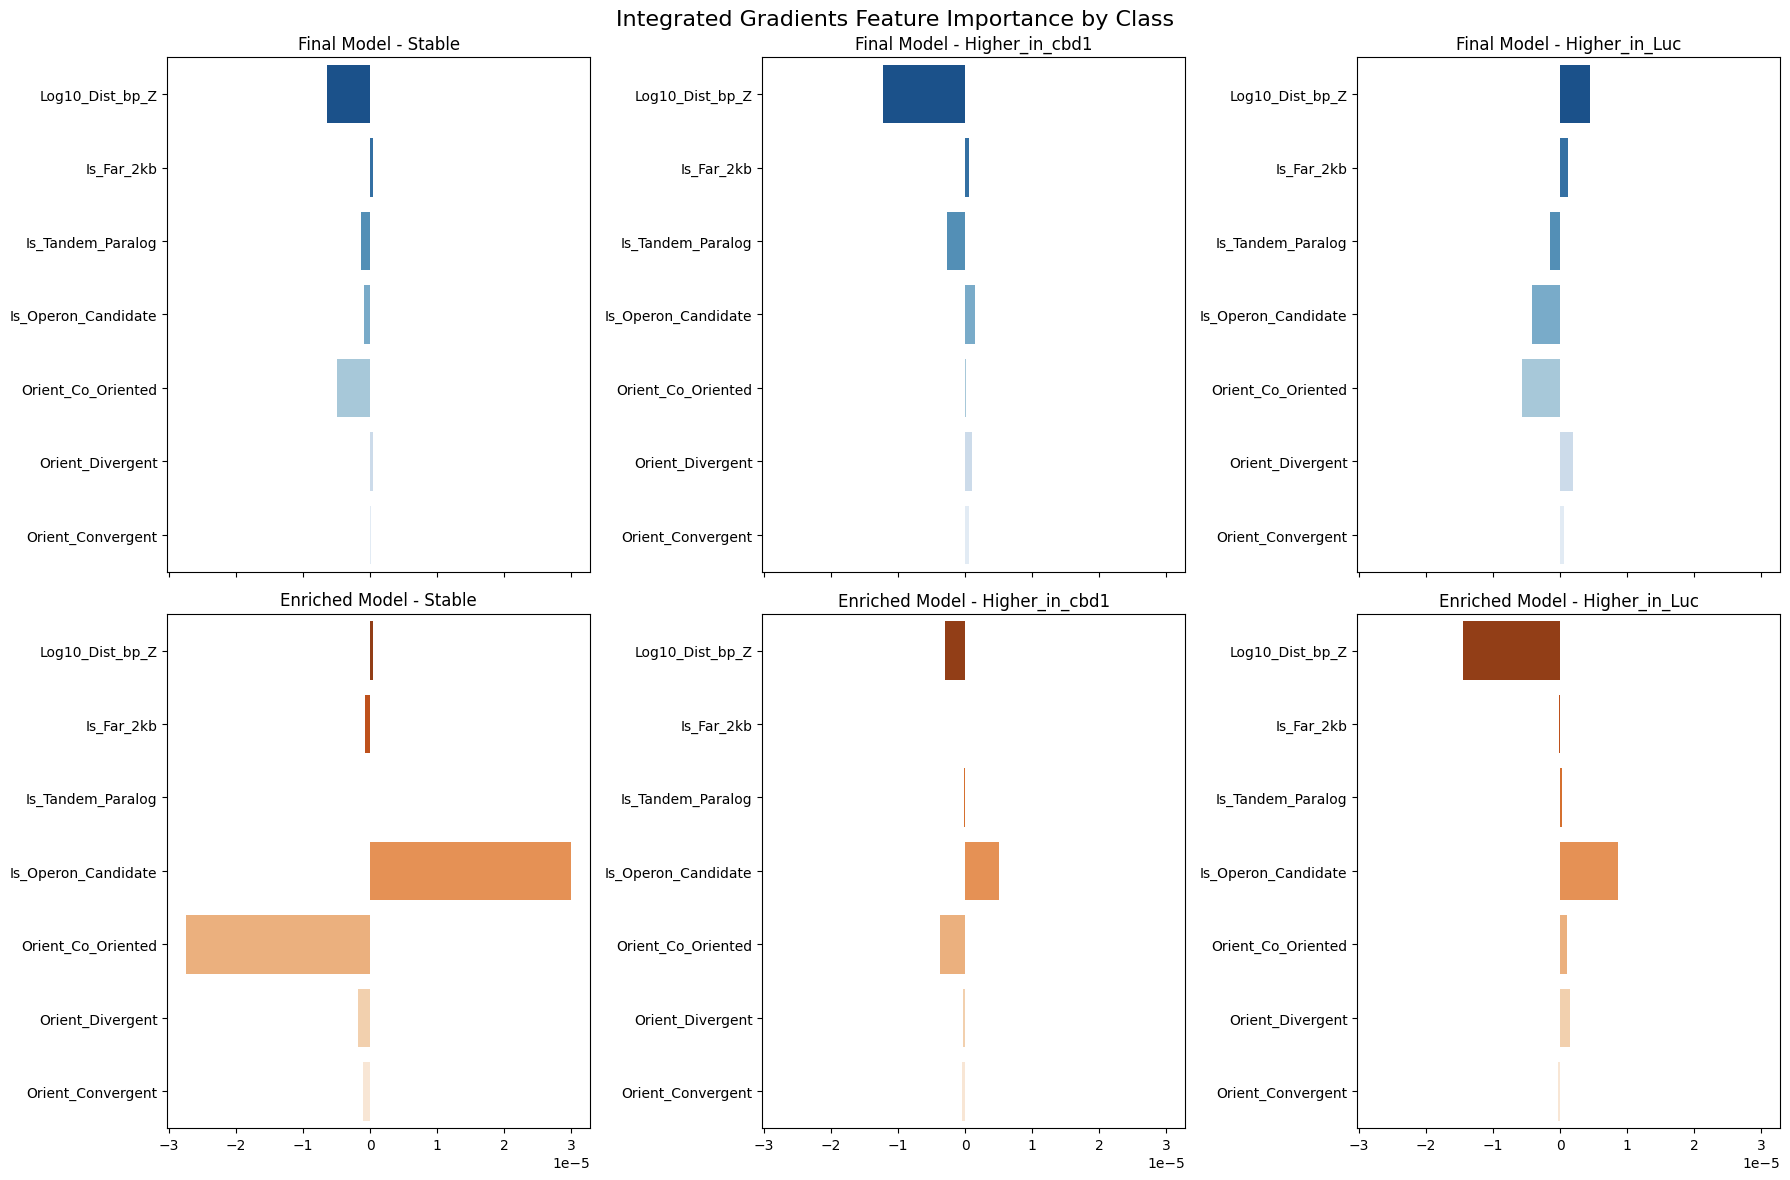

In [62]:
# Visualize the importances
fig, axes = plt.subplots(2, 3, figsize=(18, 12), sharex=True)

for i, c in enumerate(classes):
    # Final Model
    sns.barplot(x=final_model_attrs[c], y=feature_names, ax=axes[0, i], palette="Blues_r")
    axes[0, i].set_title(f"Final Model - {class_names[i]}")
    if i > 0: axes[0, i].set_ylabel("")

    # Enriched Model
    sns.barplot(x=enriched_model_attrs[c], y=feature_names, ax=axes[1, i], palette="Oranges_r")
    axes[1, i].set_title(f"Enriched Model - {class_names[i]}")
    if i > 0: axes[1, i].set_ylabel("")

plt.suptitle("Integrated Gradients Feature Importance by Class", fontsize=16)
plt.tight_layout()
plt.show()

Running Focal Loss Sensitivity Analysis (Gamma = 0.5, 1.0, 2.0)...

Training Enriched Model with Focal Loss Gamma = 0.5

Training Enriched Model with Focal Loss Gamma = 1.0

Training Enriched Model with Focal Loss Gamma = 2.0


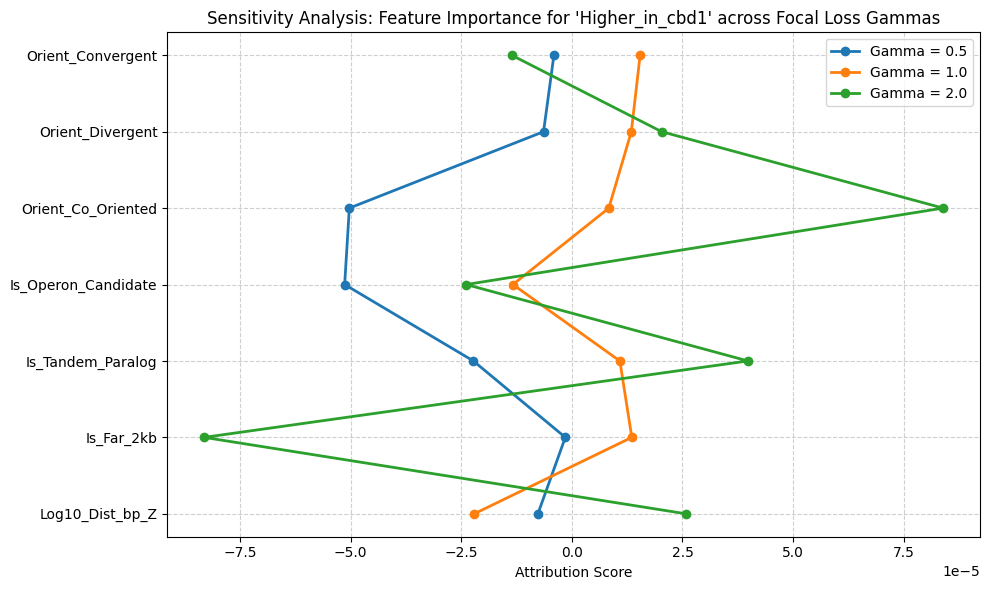

In [63]:
print("Running Focal Loss Sensitivity Analysis (Gamma = 0.5, 1.0, 2.0)...")

gammas_to_test = [0.5, 1.0, 2.0]
sensitivity_attrs = {}

for g in gammas_to_test:
    print(f"\nTraining Enriched Model with Focal Loss Gamma = {g}")
    f_criterion = FocalLoss(alpha=class_weights_tensor, gamma=g)

    temp_model = CoregulationEdgeClassifier(in_channels=x_bio.shape[1], hidden_channels=32, out_channels=16, edge_dim=num_edge_features, dropout=0.5)
    temp_predictor = torch.nn.Linear(16 * 2, num_classes)
    temp_opt = torch.optim.Adam(list(temp_model.parameters()) + list(temp_predictor.parameters()), lr=0.005, weight_decay=0.0001)

    # Train briefly (50 epochs) to capture feature reliance shifts
    for epoch in range(1, 51):
        temp_model.train()
        temp_predictor.train()
        temp_opt.zero_grad()
        node_emb = temp_model(x_bio, edge_index, edge_attr)
        feats = torch.cat([node_emb[edge_index[0]], node_emb[edge_index[1]]], dim=-1)
        out = temp_predictor(torch.nn.functional.dropout(feats, p=0.5, training=True))
        loss = f_criterion(out[train_mask], edge_labels[train_mask])
        loss.backward()
        temp_opt.step()

    # Attribute for minority class 'Higher_in_cbd1' (Class 1) to see sensitivity
    attr_c1 = get_attributions(temp_model, temp_predictor, 1)
    sensitivity_attrs[g] = attr_c1

# Plot Sensitivity Analysis
plt.figure(figsize=(10, 6))
for g in gammas_to_test:
    plt.plot(sensitivity_attrs[g], feature_names, marker='o', label=f'Gamma = {g}', linewidth=2)

plt.title("Sensitivity Analysis: Feature Importance for 'Higher_in_cbd1' across Focal Loss Gammas")
plt.xlabel("Attribution Score")
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

In [66]:
import pandas as pd

# Merge missing architectural features from the original 'data' dataframe
df_merged = df_conditional_hits.merge(
    data[['Gene1_ID', 'Gene2_ID', 'Orientation', 'Is_Tandem_Paralog', 'Log10_Dist_bp']],
    on=['Gene1_ID', 'Gene2_ID'],
    how='left'
)

def extract_tandem_paralogs(df_hits):
    """
    Filters the GATv2 predictions for tandem paralogs
    that conditionally coregulate under cbd-1(RNAi).
    """
    # Filter for tandem paralog status
    tandem_hits = df_hits[df_hits['Is_Tandem_Paralog'] == True].copy()

    # Sort primarily by GNN Probability, then by the jump from baseline correlation
    tandem_hits = tandem_hits.sort_values(
        by=['Probability', 'Coregulation_Delta'],
        ascending=[False, False]
    )

    return tandem_hits.reset_index(drop=True)

# Execute extraction
df_tandem_paralogs = extract_tandem_paralogs(df_merged)

print(f"Found {len(df_tandem_paralogs)} Conditionally Coregulated Tandem Paralogs.")
print("--- Top 10 Tandem Paralog Drivers ---")
display(df_tandem_paralogs[['Gene_1', 'Gene_2', 'Probability', 'Coregulation_Delta', 'Log10_Dist_bp', 'Orientation']].head(10))

# Export to CSV for quick lookup against WormBase
df_tandem_paralogs.to_csv("cbd1_tandem_paralog_hits_gamma2.csv", index=False)
print("\nSaved targets to: cbd1_tandem_paralog_hits_gamma2.csv")

Found 234 Conditionally Coregulated Tandem Paralogs.
--- Top 10 Tandem Paralog Drivers ---


,Gene_1,Gene_2,Probability,Coregulation_Delta,Log10_Dist_bp,Orientation
0,cest-28,cest-31,0.815334,1.155126,3.348500,Co-oriented (-> ->)
1,cest-32,cest-35.2,0.815334,0.625784,2.935003,Co-oriented (-> ->)
2,ace-4,ace-3,0.772759,0.394743,2.243038,Co-oriented (-> ->)
3,F27E5.8,F27E5.5,0.726154,1.067990,2.864511,Co-oriented (-> ->)
4,C18G1.7,C18G1.6,0.709309,0.321037,3.398808,Co-oriented (-> ->)
5,ZK488.6,ZK488.5,0.683935,1.039019,2.858537,Co-oriented (-> ->)
6,oac-27,oac-28,0.681063,0.406978,3.436481,Co-oriented (-> ->)
7,ari-1.3,ari-1.2,0.672435,1.070267,2.491362,Co-oriented (-> ->)
8,hsp-16.48,hsp-16.49,0.658832,0.415894,2.821514,Convergent (-> <-)
9,skr-20,skr-19,0.651116,0.371078,2.847573,Co-oriented (-> ->)



Saved targets to: cbd1_tandem_paralog_hits_gamma2.csv


In [67]:
!pip install gseapy -q

In [69]:
import gseapy as gp

def run_worm_go_enrichment(df_paralogs, output_dir="go_enrichment_results"):
    # Extract unique genes from the tandem paralog pairs
    target_genes = pd.concat([df_paralogs['Gene_1'], df_paralogs['Gene_2']]).unique().tolist()
    print(f"Running enrichment on {len(target_genes)} unique genes from the tandem paralog pairs...\n")

    if len(target_genes) == 0:
        print("No genes to run enrichment on!")
        return pd.DataFrame()

    try:
        # Query WormEnrichr for C. elegans specific GO terms
        # Using 'c. elegans' as the organism flag for WormEnrichr through gseapy
        enrichment = gp.enrichr(
            gene_list=target_genes,
            gene_sets=['GO_Biological_Process_2018', 'GO_Molecular_Function_2018'],
            organism='c. elegans',
            outdir=output_dir,
            cutoff=0.05 # Automatically filters by Adjusted P-value
        )

        # Isolate and sort the significant hits
        results = enrichment.results
        significant_hits = results[results['Adjusted P-value'] < 0.05].sort_values('Adjusted P-value')
        return significant_hits

    except Exception as e:
        print(f"Error querying WormEnrichr: {e}")
        return pd.DataFrame()

# Execute the enrichment on the focal-loss extracted tandem paralogs
df_go_results = run_worm_go_enrichment(df_tandem_paralogs)

# Display the top biological processes and molecular functions
if not df_go_results.empty:
    print("--- Top Enriched GO Terms ---")
    display(df_go_results[['Term', 'Overlap', 'Adjusted P-value', 'Genes']].head(15))
else:
    print("No statistically significant GO terms (Adj P < 0.05) found for this gene set, or the API encountered an issue.")

Running enrichment on 468 unique genes from the tandem paralog pairs...

--- Top Enriched GO Terms ---


,Term,Overlap,Adjusted P-value,Genes
220,UDP-glycosyltransferase activity (GO:0008194),21/96,5.405000e-13,F14B6.6;ugt-26;ugt-37;ugt-4;ugt-14;ugt-3;ugt-6...
222,"transferase activity, transferring hexosyl gro...",21/109,3.975400e-12,F14B6.6;ugt-26;ugt-37;ugt-4;ugt-14;ugt-3;ugt-6...
224,glucuronosyltransferase activity (GO:0015020),18/78,5.975500e-12,ugt-26;ugt-37;ugt-4;ugt-14;ugt-3;ugt-6;ugt-5;u...
221,heme binding (GO:0020037),15/57,5.948080e-11,ctl-2;hrg-4;cyp-33C6;cyp-35A2;cyp-35A1;cyp-35B...
223,steroid hydroxylase activity (GO:0008395),11/40,2.055265e-08,cyp-33C6;cyp-35A2;cyp-35A1;cyp-35B1;cyp-33E3;c...
225,"oxidoreductase activity, acting on paired dono...",11/40,2.055265e-08,cyp-33C6;cyp-35A2;cyp-35A1;cyp-35B1;cyp-33E3;c...
228,olfactory receptor activity (GO:0004984),20/174,6.851402e-08,sra-4;str-226;str-227;str-246;str-82;str-225;s...
0,drug catabolic process (GO:0042737),11/40,1.412995e-07,cyp-33C6;cyp-35A2;cyp-35A1;cyp-35B1;cyp-33E3;c...
1,exogenous drug catabolic process (GO:0042738),11/40,1.412995e-07,cyp-33C6;cyp-35A2;cyp-35A1;cyp-35B1;cyp-33E3;c...
236,G-protein coupled olfactory receptor activity ...,14/153,1.802798e-04,str-226;str-227;str-246;str-82;str-225;str-83;...


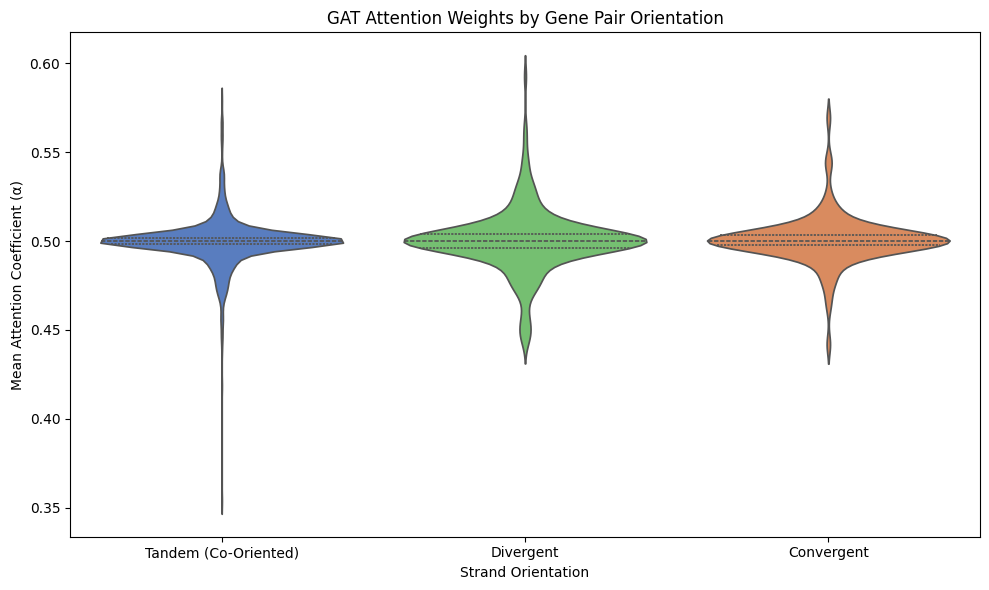

In [56]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import torch

@torch.no_grad()
def plot_orientation_attention(model, x, edge_index, edge_attr):
    model.eval()

    # Run full graph forward pass to extract weights
    _, attn_edge_index, attn_weights = model(
        x, edge_index, edge_attr, return_attention_weights=True
    )

    # Average attention weights across all attention heads
    if attn_weights.dim() > 1:
        mean_attn_weights = attn_weights.mean(dim=-1).cpu().numpy()
    else:
        mean_attn_weights = attn_weights.cpu().numpy()

    # Create a mapping from (u, v) to attention weight
    # because GAT adds self-loops (num_edges + num_nodes)
    attn_dict = {}
    for i in range(attn_edge_index.shape[1]):
        u, v = attn_edge_index[0, i].item(), attn_edge_index[1, i].item()
        attn_dict[(u, v)] = mean_attn_weights[i]

    # Get the weights specifically for our original edges
    orig_weights = []
    for i in range(edge_index.shape[1]):
        u, v = edge_index[0, i].item(), edge_index[1, i].item()
        orig_weights.append(attn_dict.get((u, v), 0.0))

    # Extract orientation columns from edge_attr
    # 4: Orient_Co_Oriented, 5: Orient_Divergent, 6: Orient_Convergent
    edge_attr_np = edge_attr.cpu().numpy()
    is_tandem = edge_attr_np[:, 4] == 1
    is_divergent = edge_attr_np[:, 5] == 1
    is_convergent = edge_attr_np[:, 6] == 1

    # Build dataframe mapping weights to orientations
    orientations = []
    for i in range(len(orig_weights)):
        if is_tandem[i]:
            orientations.append("Tandem (Co-Oriented)")
        elif is_divergent[i]:
            orientations.append("Divergent")
        elif is_convergent[i]:
            orientations.append("Convergent")
        else:
            orientations.append("Unknown")

    df = pd.DataFrame({
        "Attention_Weight": orig_weights,
        "Orientation": orientations
    })

    # Filter out any padding/unknowns
    df = df[df["Orientation"] != "Unknown"]

    # Visualize distributions with a violin plot
    plt.figure(figsize=(10, 6))
    sns.violinplot(
        x="Orientation",
        y="Attention_Weight",
        data=df,
        order=["Tandem (Co-Oriented)", "Divergent", "Convergent"],
        hue="Orientation",
        legend=False,
        palette="muted",
        inner="quartile"
    )
    plt.title("GAT Attention Weights by Gene Pair Orientation")
    plt.ylabel("Mean Attention Coefficient (α)")
    plt.xlabel("Strand Orientation")
    plt.tight_layout()
    plt.show()

# Execute visualization using our enriched_model
plot_orientation_attention(enriched_model, x_bio, edge_index, edge_attr)